In [1]:
here::i_am("Manuscript/Export_for_Luke_mapping.ipynb")

source(here::here("settings.R"))
source(here::here("utils.R"))

suppressPackageStartupMessages(library(scran))
suppressPackageStartupMessages(library(scater))
suppressPackageStartupMessages(library(Seurat))
suppressPackageStartupMessages(library(dplyr))
suppressPackageStartupMessages(library(ArchR))

BPPARAM <- BiocParallel::bpparam()
BPPARAM$workers = 21

# Multi core using future - built in to seurat
plan("multicore", workers = 16)
options(future.globals.maxSize = 50 * 1024 ^ 3) # for 50 Gb RAM

here() starts at /rds/project/rds-SDzz0CATGms/users/bt392/10_Eomes_invitro_gut/code


                                                   / |
                                                 /    \
            .                                  /      |.
            \\\                              /        |.
              \\\                          /           `|.
                \\\                      /              |.
                  \                    /                |\
                  \\#####\           /                  ||
                ==###########>      /                   ||
                 \\##==......\    /                     ||
            ______ =       =|__ /__                     ||      \\\
        ,--' ,----`-,__ ___/'  --,-`-===================##========>
       \               '        ##_______ _____ ,--,__,=##,__   ///
        ,    __==    ___,-,__,--'#'  ==='      `-'    | ##,-/
        -,____,---'       \\####\\________________,--\\_##,/
        

In [2]:
args = list()
# RNA_sce
args$rna_sce = file.path(io$basedir, 'processed/rna/SingleCellExperiment.rds')

# Metadata
args$metadata = file.path(io$basedir, 'results/rna_atac/combined_metadata.txt.gz')

# Mapping metadata
args$mapping = file.path(io$basedir, 'results/rna/mapping/sample_metadata_after_mapping.txt.gz')

# outdir
args$outdir = file.path(io$basedir, 'results/manuscript/spatial_mapping/')
dir.create(args$outdir, showWarnings = F, recursive = T)


In [27]:
# Load meta
meta = fread(args$metadata)

In [28]:
colnames(meta)

[1] "cell"                      "barcode"                  
 [3] "sample"                    "nFeature_RNA"             
 [5] "nCount_RNA"                "mitochondrial_percent_RNA"
 [7] "ribosomal_percent_RNA"     "alias"                    
 [9] "day"                       "genotype"                 
[11] "pass_rnaQC"                "doublet_score"            
[13] "doublet_call"              "celltype"                 
[15] "celltype.score"            "closest.cell"             
[17] "day_celltype"              "celltype_genotype"        
[19] "TSSEnrichment_atac"        "ReadsInTSS_atac"          
[21] "PromoterRatio_atac"        "NucleosomeRatio_atac"     
[23] "nFrags_atac"               "BlacklistRatio_atac"      
[25] "pass_atacQC"

## RNA

In [29]:
# load sce
rna.sce <- load_SingleCellExperiment(args$rna_sce, normalise = TRUE, cells = meta$cell)
colData(rna.sce) = meta %>% as.data.frame() %>% tibble::column_to_rownames('cell') %>% DataFrame()

# Convert to Seurat
seurat = as.Seurat(rna.sce)

In [11]:
seurat

An object of class Seurat 
32285 features across 46547 samples within 1 assay 
Active assay: RNA (32285 features, 0 variable features)

In [12]:
seurat <- FindVariableFeatures(seurat, selection.method = "vst", nfeatures = 2000)

In [13]:
seurat <- ScaleData(seurat) # vars.to.regress

Centering and scaling data matrix



In [14]:
seurat <- RunPCA(seurat, features = VariableFeatures(object = seurat))

PC_ 1 
Positive:  Epcam, Igfbp2, Dnmt3b, Pid1, Ftl1-ps1, Ror1, Emb, Rian, L1td1, Alg13 
	   Meg3, Nrcam, Hs6st2, Tet1, Akap12, Mkrn1, Snhg3, Fgf5, Ppp4r4, Adam23 
	   Gclm, Tgfbr3, B830012L14Rik, Pim2, Cldn7, Frmd5, Dab1, Kcnj3, Tdgf1, 1700019D03Rik 
Negative:  Greb1l, Meis2, Kif26b, Tmem132c, Pcsk5, Pcdh19, Fbn2, Meis1, Lama1, Ifitm1 
	   Foxp1, Aldh1a2, Sdk2, Hoxb3os, Notch1, Maml3, Dach1, Pax3, Lrig3, Tenm4 
	   Maml2, Hmga2, Prkg1, Mdk, Tshz1, Dll1, Cdh2, Mllt3, Ncam1, Kalrn 
PC_ 2 
Positive:  Gpc6, Slit3, Fst, Ppp4r4, T, Mcc, Tcf12, Nrcam, Klhl32, Gria4 
	   Grip1, Zdbf2, Adgrl2, Xkr4, Pbx3, Magi2, Tasp1, Dock11, Pcdh7, Rfx3 
	   Kcnj3, Tgfbr3, Sema6a, Dab1, Dapk1, Dpp10, Pid1, Alcam, Fgf5, Fgf8 
Negative:  Morc1, Lncenc1, Spp1, Dppa5a, Sox2, Zfp42, Triml2, Gm49504, Dnah8, Lima1 
	   Zfp981, Zfp980, Nr5a2, Gm2381, Esrrb, Inpp5d, Fbxo15, Rnf17, Triml1, 2410141K09Rik 
	   Trap1a, Zfp936, AU018091, Zfp978, Zfp600, Sdc4, Lrrc31, Fgf4, Pecam1, Smc1b 
PC_ 3 
Positive:  Lef1, Ptn, Pcsk5,

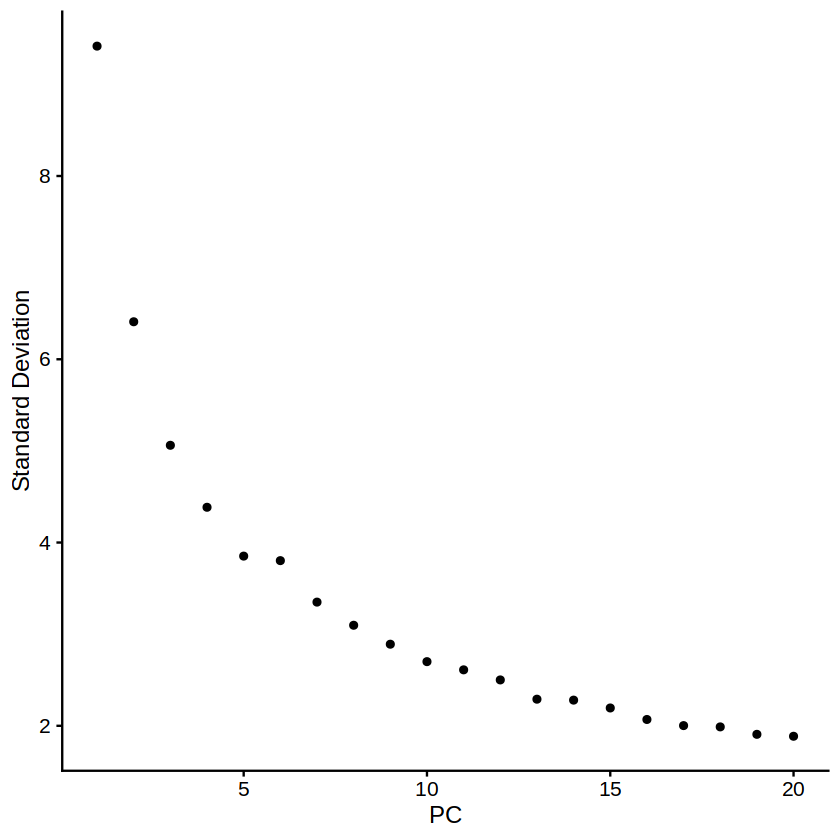

In [15]:
ElbowPlot(seurat)

In [16]:
seurat <- FindNeighbors(seurat, dims = 1:15)


Computing nearest neighbor graph

Computing SNN



In [17]:
seurat <- RunUMAP(seurat, dims = 1:15)


Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
22:08:11 UMAP embedding parameters a = 0.9922 b = 1.112

22:08:11 Read 46547 rows and found 15 numeric columns

22:08:11 Using Annoy for neighbor search, n_neighbors = 30

22:08:11 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

22:08:14 Writing NN index file to temp file /tmp/RtmpfWo2ZK/file585a13a54f764

22:08:14 Searching Annoy index using 16 threads, search_k = 3000

22:08:15 Annoy recall = 100%

22:08:16 Commencing smooth kNN distance calibration using 16 threads
 with target n_neigh

In [22]:
colnames(seurat@meta.data)

[1] "orig.ident"                "nCount_RNA"               
 [3] "nFeature_RNA"              "barcode"                  
 [5] "sample"                    "mitochondrial_percent_RNA"
 [7] "ribosomal_percent_RNA"     "alias"                    
 [9] "day"                       "genotype"                 
[11] "pass_rnaQC"                "doublet_score"            
[13] "doublet_call"              "celltype"                 
[15] "celltype.score"            "closest.cell"             
[17] "day_celltype"              "celltype_genotype"        
[19] "TSSEnrichment_atac"        "ReadsInTSS_atac"          
[21] "PromoterRatio_atac"        "NucleosomeRatio_atac"     
[23] "nFrags_atac"               "BlacklistRatio_atac"      
[25] "pass_atacQC"

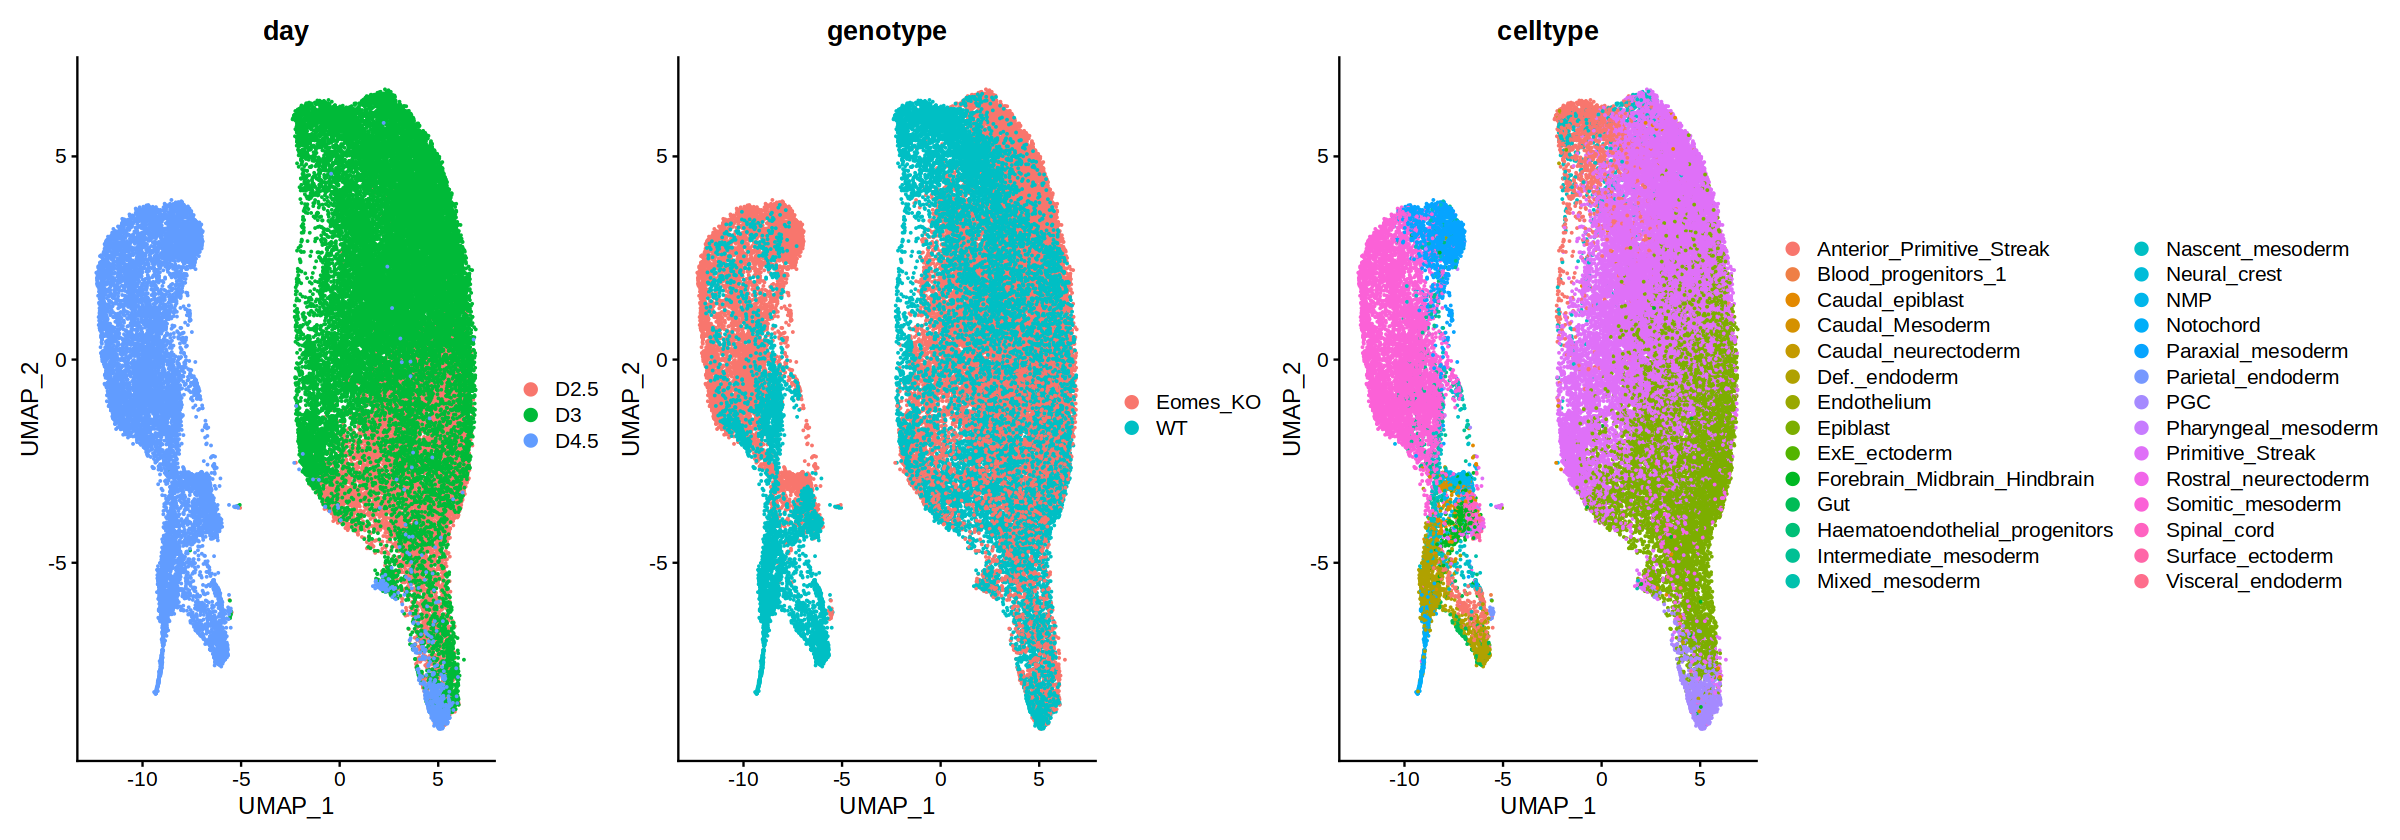

In [21]:
options(repr.plot.width = 20, repr.plot.height = 7)
DimPlot(seurat, reduction = "umap", group.by = c('day', 'genotype', 'celltype'))

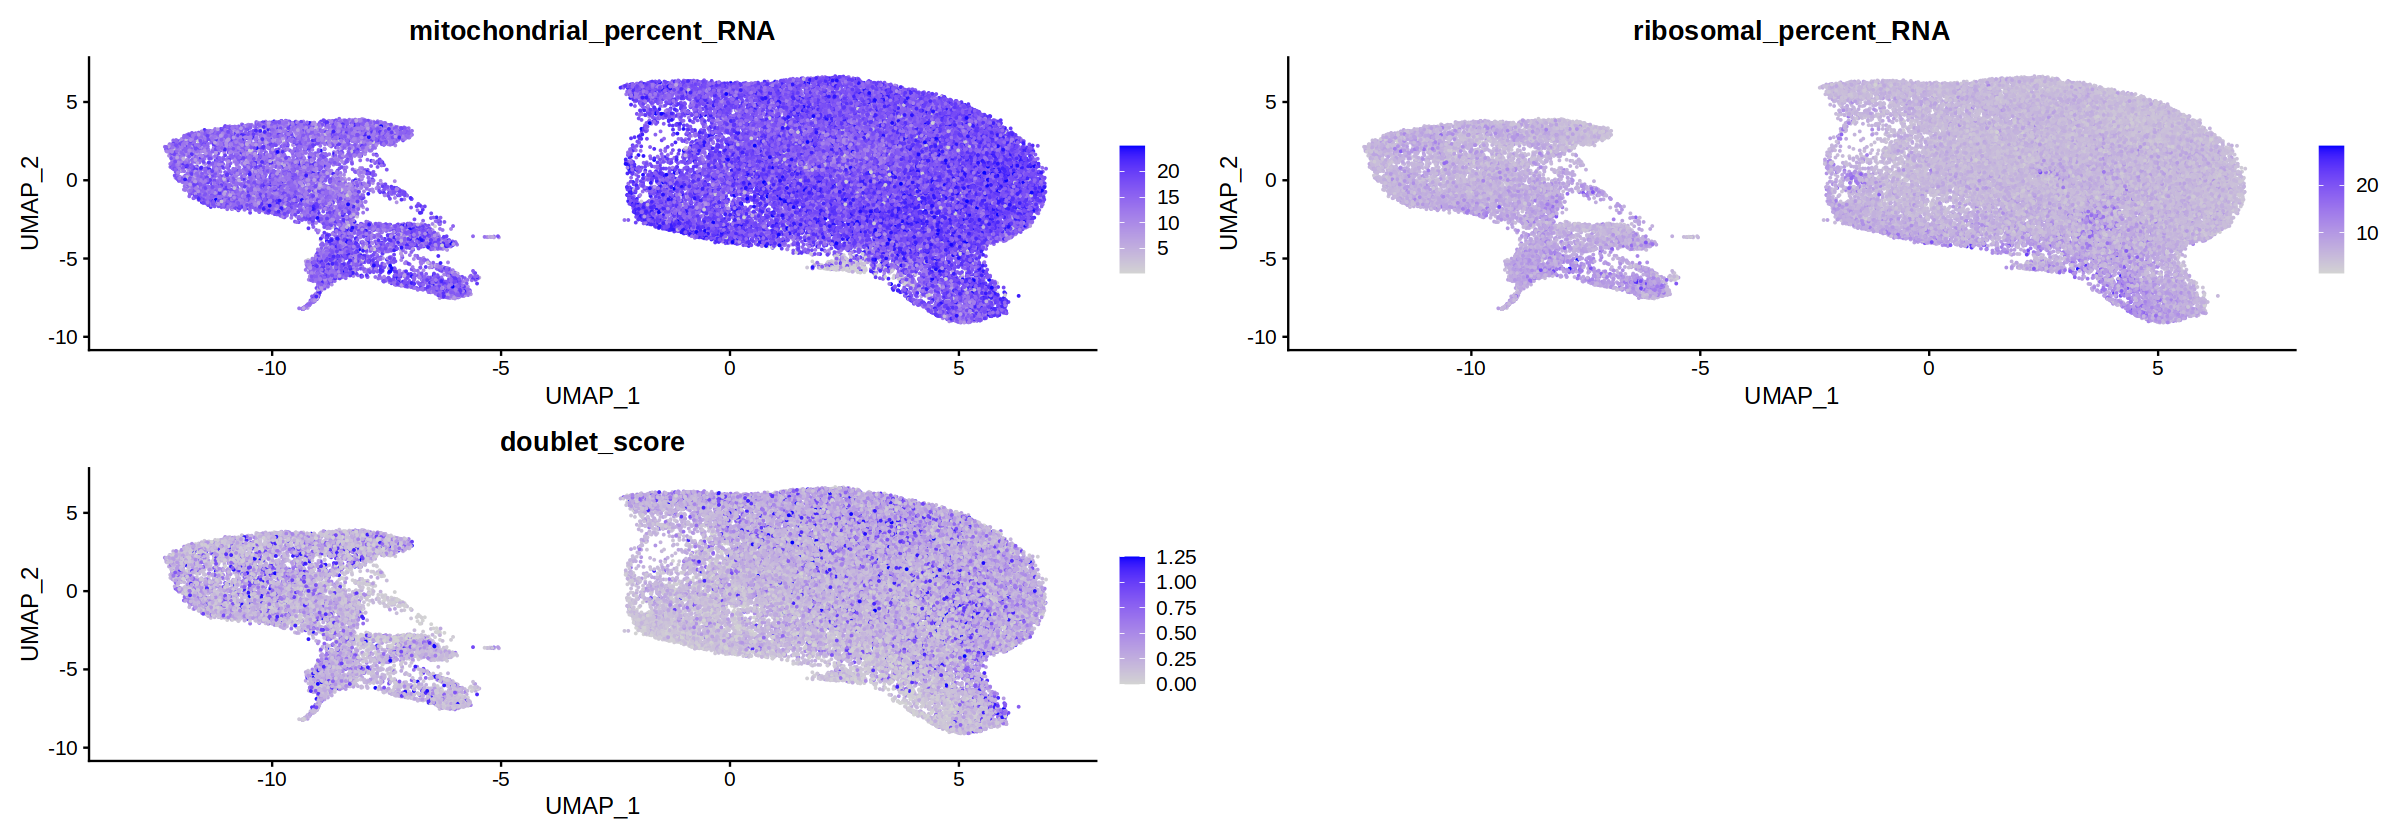

In [23]:
FeaturePlot(seurat, reduction = "umap", features = c('mitochondrial_percent_RNA', 'ribosomal_percent_RNA', 'doublet_score'))

In [24]:
saveRDS(seurat, file.path(args$outdir, 'seurat_object.rds'))

In [3]:
seurat = readRDS(file.path(args$outdir, 'seurat_object.rds'))

In [12]:
d45_meta = fread(file.path(io$basedir, 'results/manuscript/day_45/', 'd45_celltypes.txt.gz'))[, .(cell, celltype_manual)]
d253_meta = fread(file.path(io$basedir, 'results/manuscript/day_253/', 'd253_celltypes.txt.gz'))[, .(cell, celltype_manual)]
celltype_meta = rbind(d253_meta, d45_meta)

In [18]:
celltype_meta = celltype_meta[match(colnames(seurat), cell)]
summary(colnames(seurat) == celltype_meta$cell)

   Mode    TRUE 
logical   46547 

In [16]:
seurat@meta.data$celltype_manual = celltype_meta$celltype_manual

An object of class Seurat 
32285 features across 46547 samples within 1 assay 
Active assay: RNA (32285 features, 2000 variable features)
 2 dimensional reductions calculated: pca, umap

In [19]:
head(seurat@meta.data)

,orig.ident,nCount_RNA,nFeature_RNA,barcode,sample,mitochondrial_percent_RNA,ribosomal_percent_RNA,alias,day,genotype,⋯,closest.cell,day_celltype,celltype_genotype,TSSEnrichment_atac,ReadsInTSS_atac,PromoterRatio_atac,NucleosomeRatio_atac,nFrags_atac,BlacklistRatio_atac,pass_atacQC
,<fct>,<int>,<int>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<dbl>,<int>,<dbl>,<dbl>,<int>,<dbl>,<lgl>
RBG43471#AAACAGCCAACACTTG-1,SeuratProject,10001,3776,AAACAGCCAACACTTG-1,RBG43471,17.23,6.23,D2.5_WT_rep1,D2.5,WT,⋯,cell_6125,D2.5-WT,Epiblast-WT,9.77,2591,0.17,1.40,33521,0.02,TRUE
RBG43471#AAACAGCCACATACTG-1,SeuratProject,7227,3129,AAACAGCCACATACTG-1,RBG43471,15.65,6.03,D2.5_WT_rep1,D2.5,WT,⋯,cell_5920,D2.5-WT,Epiblast-WT,12.63,1288,0.21,1.47,12563,0.02,TRUE
RBG43471#AAACAGCCACGAATTT-1,SeuratProject,11338,3791,AAACAGCCACGAATTT-1,RBG43471,22.12,8.18,D2.5_WT_rep1,D2.5,WT,⋯,cell_90477,D2.5-WT,Epiblast-WT,18.36,1363,0.24,1.15,10207,0.02,TRUE
RBG43471#AAACAGCCAGTTAGCC-1,SeuratProject,6358,2559,AAACAGCCAGTTAGCC-1,RBG43471,24.55,7.80,D2.5_WT_rep1,D2.5,WT,⋯,cell_119050,D2.5-WT,Rostral_neurectoderm-WT,14.87,1374,0.23,1.42,11514,0.02,TRUE
RBG43471#AAACATGCAAGTCGCT-1,SeuratProject,11513,4118,AAACATGCAAGTCGCT-1,RBG43471,16.92,6.19,D2.5_WT_rep1,D2.5,WT,⋯,cell_105223,D2.5-WT,Epiblast-WT,15.28,1605,0.21,1.38,14524,0.02,TRUE
RBG43471#AAACATGCAATTGAAG-1,SeuratProject,9012,3391,AAACATGCAATTGAAG-1,RBG43471,18.59,8.67,D2.5_WT_rep1,D2.5,WT,⋯,cell_90752,D2.5-WT,Primitive_Streak-WT,11.57,2612,0.18,1.43,30417,0.02,TRUE


# Plotting

In [3]:
new_meta = readRDS(file.path(args$outdir, 'merged_query_meta.Rds'))

In [10]:
clusters = fread(file.path(io$basedir, 'results/manuscript/day_45/', 'd45_celltypes_highres.txt.gz'))

In [19]:
meta_updated = merge(new_meta, clusters[,c('cell', 'seurat_clusters')], by.x = "cell_ID", by.y = "cell")

In [20]:
head(meta_updated)

,cell_ID,celltype,day_celltype,AP,DV,joint_clusters_pass_QC,refined_annotation,UMAP_1,UMAP_2,dim1,dim2,embryo,nearest_cell,nearest_cell_seqFISH,dataset,seurat_clusters
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<int>
1,RBG43477#AAACAGCCAACACCTA-1,Nascent_mesoderm,D4.5-Eomes_KO,76.36633,74.35254,TRUE,Optic vesicle,-8.63357350,5.501548,755.2728,1199.8791,embryo2,embryo2_Pos35_cell62,embryo2_Pos35_cell187,query,2
2,RBG43477#AAACAGCCAATGAAGC-1,Somitic_mesoderm,D4.5-Eomes_KO,16.55162,33.38043,TRUE,Somitic mesoderm,-0.08864229,1.789511,1637.1097,1780.1204,embryo3,embryo3_Pos39_cell275,embryo3_Pos38_cell571,query,3
3,RBG43477#AAACAGCCAGCATTAT-1,Paraxial_mesoderm,D4.5-Eomes_KO,56.70981,16.73341,TRUE,Posterior somitic tissues,3.23140314,2.564687,528.8525,406.8999,embryo2,embryo2_Pos45_cell269,embryo2_Pos45_cell509,query,8
4,RBG43477#AAACAGCCAGGAAGCC-1,Rostral_neurectoderm,D4.5-Eomes_KO,NA,NA,TRUE,Amniotic ectoderm,-6.77142331,-2.933988,1193.2847,393.1305,embryo2,cell_48176,embryo2_Pos48_cell176,query,2
5,RBG43477#AAACAGCCATGGAGGC-1,Somitic_mesoderm,D4.5-Eomes_KO,45.53227,43.65192,TRUE,Anterior LPM,3.60139969,-1.051086,409.1968,301.3801,embryo1,embryo3_Pos21_cell457,embryo1_Pos23_cell278,query,0
6,RBG43477#AAACATGCAAGTAAGC-1,Somitic_mesoderm,D4.5-Eomes_KO,19.09076,45.78082,TRUE,Somitic mesoderm,0.46407318,1.469006,1696.4694,1599.2430,embryo3,cell_139329,embryo3_Pos39_cell187,query,3


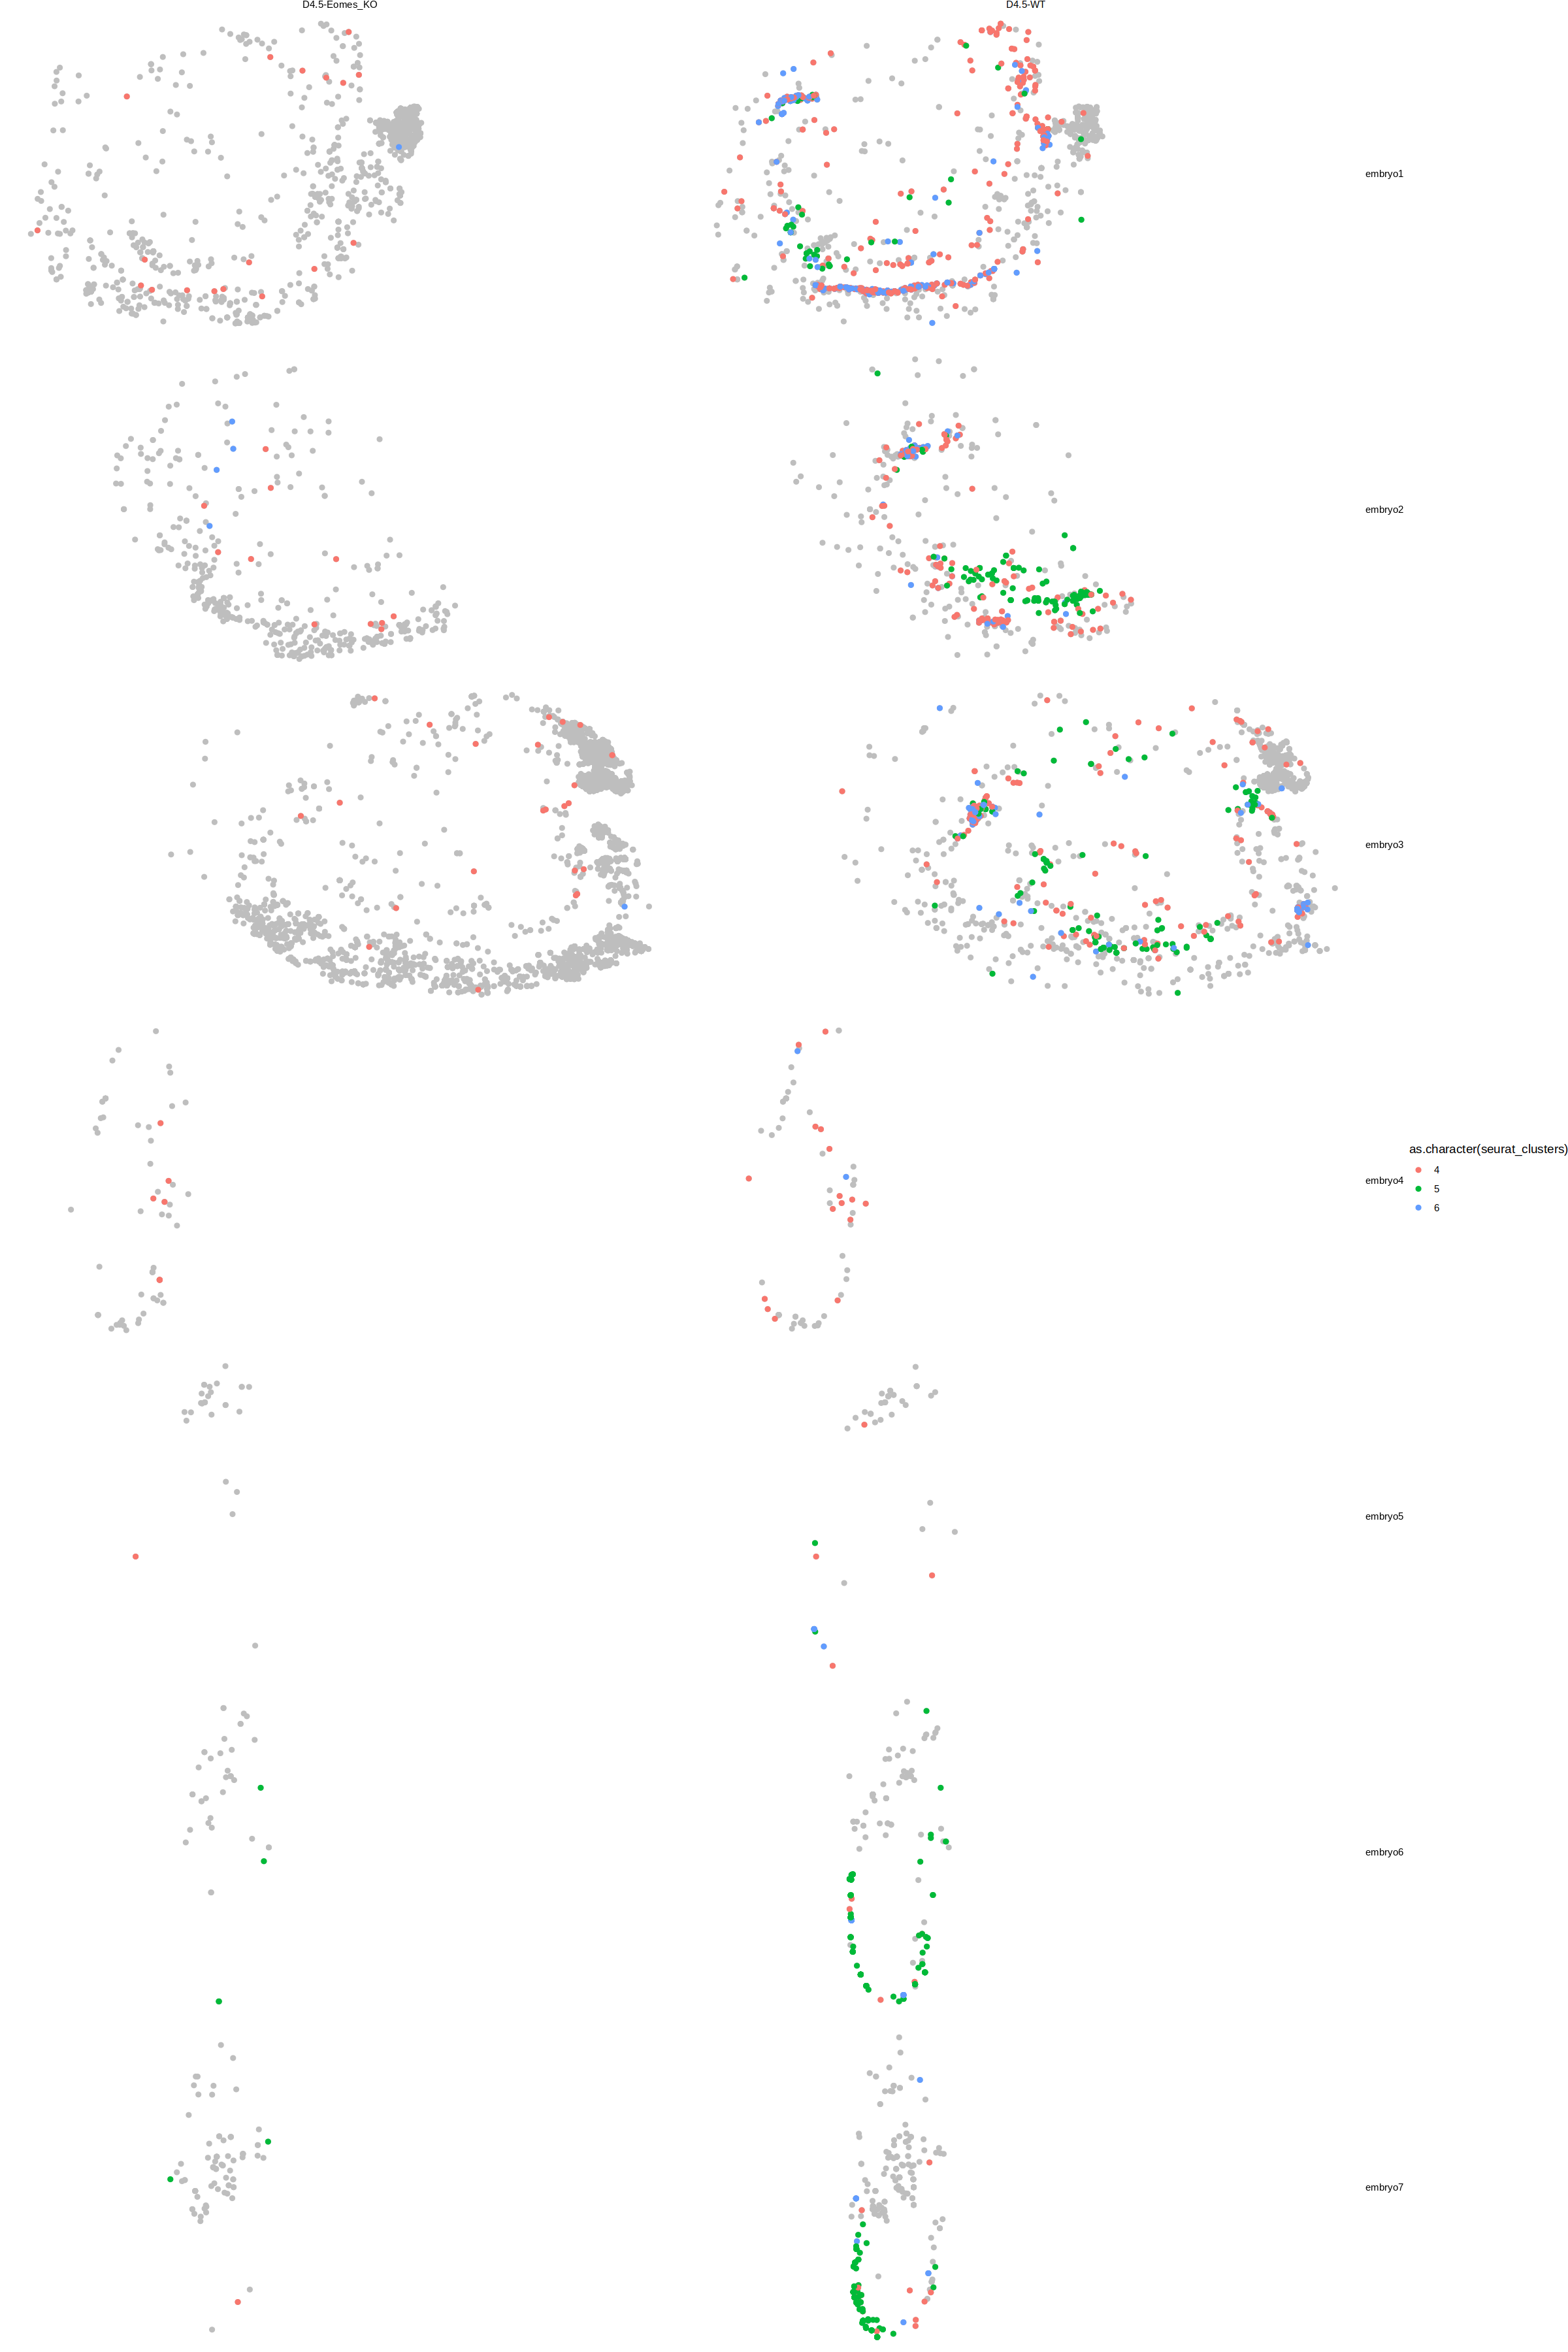

In [24]:
options(repr.plot.width = 20, repr.plot.height = 30)

ggplot(meta_updated, aes(dim1, dim2)) + 
    geom_point(color = 'grey') + 
    geom_point(data = as.data.table(meta_updated)[seurat_clusters %in% c(4,5,6)], aes(color = as.character(seurat_clusters))) + 
    #scale_color_manual(values = opts$celltype_ext.colors) + 
    facet_grid(cols = vars(day_celltype), rows = vars(embryo), scales = 'free') + 
    theme_void() + 
    theme(
        legend.position = 'right'
    )


In [33]:
seurat@meta.data$dim1 = as.data.table(meta_updated)[match(colnames(seurat), cell_ID)]$dim1
seurat@meta.data$dim2 = as.data.table(meta_updated)[match(colnames(seurat), cell_ID)]$dim2

In [36]:
seurat = NormalizeData(seurat)

In [38]:
gene = 'Sox17'
as.numeric(seurat@assays$RNA@data[gene,])

[1] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
    [8] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
   [15] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
   [22] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
   [29] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
   [36] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
   [43] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
   [50] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
   [57] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
   [64] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
   [71] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
   [78] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
   [85] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
   [92] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
   [99] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [106] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [113] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [120] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [127] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [134] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [141] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [148] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [155] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [162] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [169] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [176] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [183] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [190] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [197] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [204] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [211] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [218] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [225] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [232] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [239] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [246] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [253] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [260] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [267] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [274] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [281] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [288] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [295] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [302] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [309] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [316] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [323] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [330] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [337] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [344] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [351] 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.0000000
  [358] 0.0000000 0.000000

In [48]:
head(colnames(seurat@assays$RNA@data[gene,as.data.table(meta_updated)[seurat_clusters %in% c(4,5,6)]$cell_ID]))

NULL

In [49]:
summary(as.data.table(meta_updated)[seurat_clusters %in% c(4,5,6)]$cell_ID == colnames(seurat[,as.data.table(meta_updated)[seurat_clusters %in% c(4,5,6)]$cell_ID]))

   Mode    TRUE 
logical    2526 

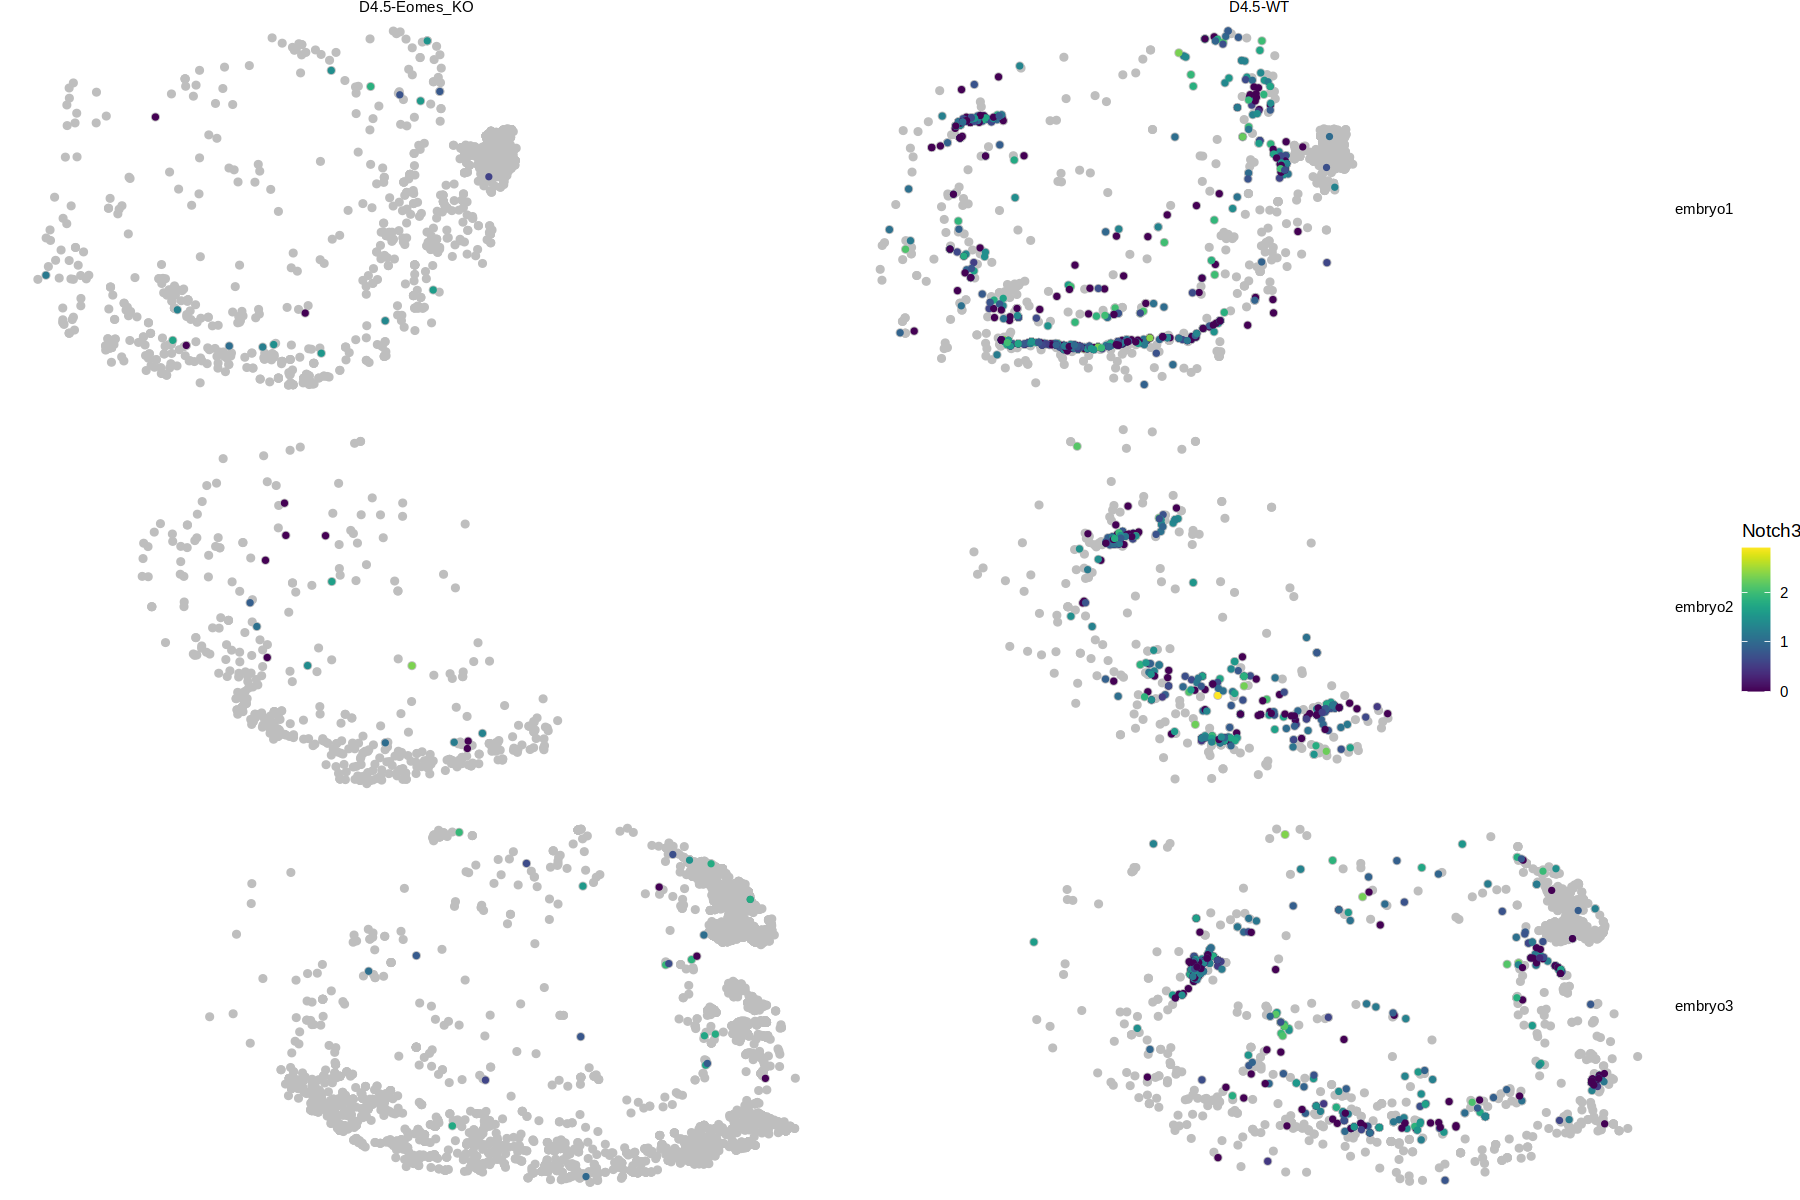

In [71]:
gene = 'Notch3'
options(repr.plot.width = 15, repr.plot.height = 10)
ggplot(as.data.table(meta_updated)[embryo %in% c(paste0('embryo', 1:3))], aes(dim1, dim2, color = as.numeric(seurat@assays$RNA@data[gene,as.data.table(meta_updated)[embryo %in% c(paste0('embryo', 1:3))]$cell_ID]))) + 
    geom_point(color = 'grey') + 
    geom_point(data = as.data.table(meta_updated)[embryo %in% c(paste0('embryo', 1:3)) & seurat_clusters %in% c(4,5,6)], size = 1, aes(color = as.numeric(seurat@assays$RNA@data[gene,as.data.table(meta_updated)[embryo %in% c(paste0('embryo', 1:3)) & seurat_clusters %in% c(4,5,6)]$cell_ID]))) + 
    viridis::scale_color_viridis(name = gene) +  
    facet_grid(cols = vars(day_celltype), rows = vars(embryo), scales = 'free') + 
    theme_void() + 
    theme(
        legend.position = 'right'
    )


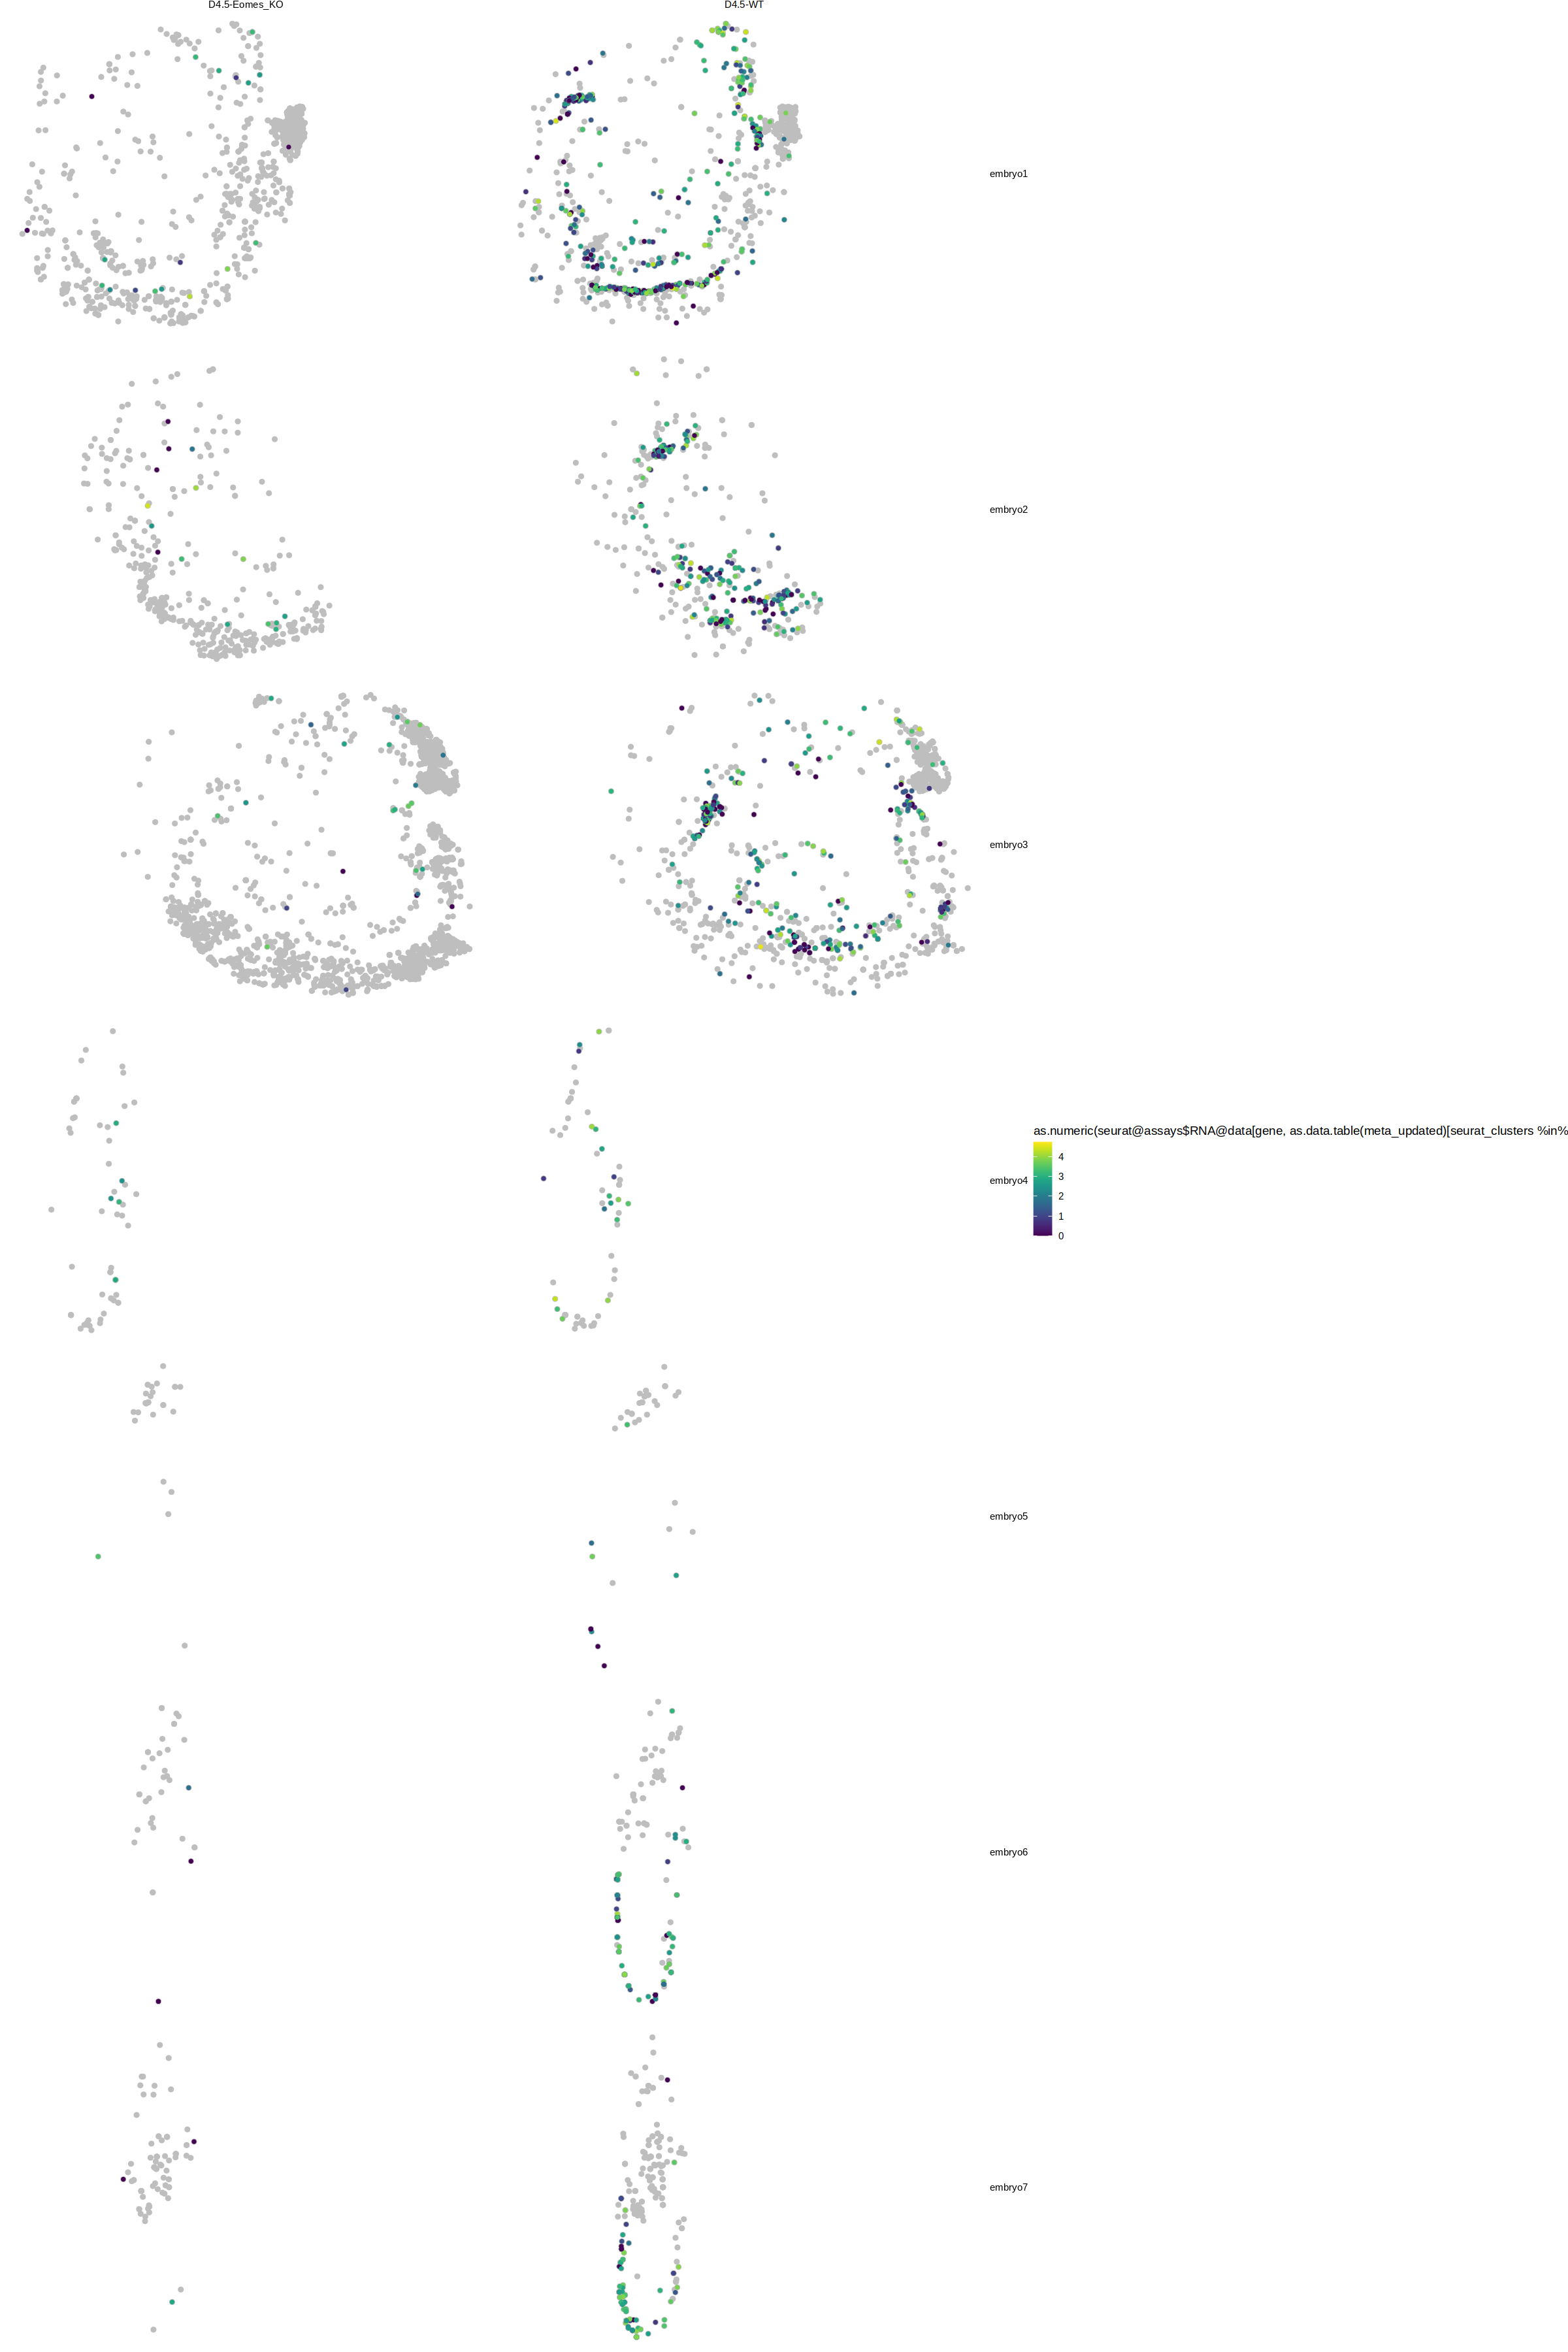

In [46]:
gene = 'Lefty1'
ggplot(meta_updated, aes(dim1, dim2)) + 
    geom_point(color = 'grey') + 
    geom_point(data = as.data.table(meta_updated)[seurat_clusters %in% c(4,5,6)], size = 1, aes(color = as.numeric(seurat@assays$RNA@data[gene,as.data.table(meta_updated)[seurat_clusters %in% c(4,5,6)]$cell_ID]))) + 
    viridis::scale_color_viridis() +  
    facet_grid(cols = vars(day_celltype), rows = vars(embryo), scales = 'free') + 
    theme_void() + 
    theme(
        legend.position = 'right'
    )


In [30]:
seurat

cell_ID,celltype,day_celltype,AP,DV,joint_clusters_pass_QC,refined_annotation,UMAP_1,UMAP_2,dim1,dim2,embryo,nearest_cell,nearest_cell_seqFISH,dataset,seurat_clusters
<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<int>
RBG43477#AAACAGCCAACACCTA-1,Nascent_mesoderm,D4.5-Eomes_KO,76.36633,74.35254,TRUE,Optic vesicle,-8.63357350,5.5015481,755.27277,1199.8791,embryo2,embryo2_Pos35_cell62,embryo2_Pos35_cell187,query,2
RBG43477#AAACAGCCAATGAAGC-1,Somitic_mesoderm,D4.5-Eomes_KO,16.55162,33.38043,TRUE,Somitic mesoderm,-0.08864229,1.7895109,1637.10971,1780.1204,embryo3,embryo3_Pos39_cell275,embryo3_Pos38_cell571,query,3
RBG43477#AAACAGCCAGCATTAT-1,Paraxial_mesoderm,D4.5-Eomes_KO,56.70981,16.73341,TRUE,Posterior somitic tissues,3.23140314,2.5646873,528.85253,406.8999,embryo2,embryo2_Pos45_cell269,embryo2_Pos45_cell509,query,8
RBG43477#AAACAGCCAGGAAGCC-1,Rostral_neurectoderm,D4.5-Eomes_KO,NA,NA,TRUE,Amniotic ectoderm,-6.77142331,-2.9339883,1193.28468,393.1305,embryo2,cell_48176,embryo2_Pos48_cell176,query,2
RBG43477#AAACAGCCATGGAGGC-1,Somitic_mesoderm,D4.5-Eomes_KO,45.53227,43.65192,TRUE,Anterior LPM,3.60139969,-1.0510860,409.19680,301.3801,embryo1,embryo3_Pos21_cell457,embryo1_Pos23_cell278,query,0
RBG43477#AAACATGCAAGTAAGC-1,Somitic_mesoderm,D4.5-Eomes_KO,19.09076,45.78082,TRUE,Somitic mesoderm,0.46407318,1.4690059,1696.46943,1599.2430,embryo3,cell_139329,embryo3_Pos39_cell187,query,3
RBG43477#AAACATGCAATAACCT-1,Somitic_mesoderm,D4.5-Eomes_KO,20.43017,45.98474,TRUE,Posterior somitic tissues,1.05457416,2.0353978,1686.76098,592.3732,embryo3,ext_cell_52556,embryo3_Pos20_cell714,query,9
RBG43477#AAACATGCAGAATGAC-1,Somitic_mesoderm,D4.5-Eomes_KO,14.02523,28.66394,TRUE,Presomitic mesoderm,-0.51805195,0.9458167,1615.98098,1855.5254,embryo3,embryo3_Pos38_cell62,embryo3_Pos38_cell153,query,0
RBG43477#AAACATGCAGCAGGTA-1,Paraxial_mesoderm,D4.5-Eomes_KO,51.95407,21.12844,TRUE,Sclerotome,2.41765097,2.5456717,538.40416,352.4168,embryo2,embryo2_Pos50_cell53,embryo2_Pos45_cell237,query,8


In [13]:
head(meta_updated)

,cell_ID,celltype.x,day_celltype.x,AP,DV,joint_clusters_pass_QC,refined_annotation,UMAP_1,UMAP_2,dim1,⋯,celltype_genotype,TSSEnrichment_atac,ReadsInTSS_atac,PromoterRatio_atac,NucleosomeRatio_atac,nFrags_atac,BlacklistRatio_atac,pass_atacQC,RNA_snn_res.0.9,seurat_clusters
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,⋯,<chr>,<dbl>,<int>,<dbl>,<dbl>,<int>,<dbl>,<lgl>,<int>,<int>
1,RBG43477#AAACAGCCAACACCTA-1,Nascent_mesoderm,D4.5-Eomes_KO,76.36633,74.35254,TRUE,Optic vesicle,-8.63357350,5.501548,755.2728,⋯,Nascent_mesoderm-Eomes_KO,25.20,1387,0.36,0.83,7041,0.03,TRUE,2,2
2,RBG43477#AAACAGCCAATGAAGC-1,Somitic_mesoderm,D4.5-Eomes_KO,16.55162,33.38043,TRUE,Somitic mesoderm,-0.08864229,1.789511,1637.1097,⋯,Somitic_mesoderm-Eomes_KO,14.20,2396,0.20,1.53,23527,0.02,TRUE,3,3
3,RBG43477#AAACAGCCAGCATTAT-1,Paraxial_mesoderm,D4.5-Eomes_KO,56.70981,16.73341,TRUE,Posterior somitic tissues,3.23140314,2.564687,528.8525,⋯,Paraxial_mesoderm-Eomes_KO,12.22,2339,0.21,1.19,20992,0.02,TRUE,8,8
4,RBG43477#AAACAGCCAGGAAGCC-1,Rostral_neurectoderm,D4.5-Eomes_KO,NA,NA,TRUE,Amniotic ectoderm,-6.77142331,-2.933988,1193.2847,⋯,Rostral_neurectoderm-Eomes_KO,14.66,2740,0.22,1.19,23204,0.02,TRUE,2,2
5,RBG43477#AAACAGCCATGGAGGC-1,Somitic_mesoderm,D4.5-Eomes_KO,45.53227,43.65192,TRUE,Anterior LPM,3.60139969,-1.051086,409.1968,⋯,Somitic_mesoderm-Eomes_KO,15.94,1328,0.21,1.77,13001,0.02,TRUE,0,0
6,RBG43477#AAACATGCAAGTAAGC-1,Somitic_mesoderm,D4.5-Eomes_KO,19.09076,45.78082,TRUE,Somitic mesoderm,0.46407318,1.469006,1696.4694,⋯,Somitic_mesoderm-Eomes_KO,16.19,1929,0.20,1.41,18457,0.02,TRUE,3,3


In [11]:
head(clusters)

cell,orig.ident,nCount_RNA,nFeature_RNA,barcode,sample,mitochondrial_percent_RNA,ribosomal_percent_RNA,alias,day,⋯,celltype_genotype,TSSEnrichment_atac,ReadsInTSS_atac,PromoterRatio_atac,NucleosomeRatio_atac,nFrags_atac,BlacklistRatio_atac,pass_atacQC,RNA_snn_res.0.9,seurat_clusters
<chr>,<chr>,<int>,<int>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,⋯,<chr>,<dbl>,<int>,<dbl>,<dbl>,<int>,<dbl>,<lgl>,<int>,<int>
RBG43477#AAACAGCCAACACCTA-1,SeuratProject,3455,2075,AAACAGCCAACACCTA-1,RBG43477,0.64,6.77,D4.5_KO_rep1,D4.5,⋯,Nascent_mesoderm-Eomes_KO,25.20,1387,0.36,0.83,7041,0.03,TRUE,2,2
RBG43477#AAACAGCCAATGAAGC-1,SeuratProject,6411,2526,AAACAGCCAATGAAGC-1,RBG43477,17.80,4.93,D4.5_KO_rep1,D4.5,⋯,Somitic_mesoderm-Eomes_KO,14.20,2396,0.20,1.53,23527,0.02,TRUE,3,3
RBG43477#AAACAGCCAGCATTAT-1,SeuratProject,8305,3231,AAACAGCCAGCATTAT-1,RBG43477,14.55,6.63,D4.5_KO_rep1,D4.5,⋯,Paraxial_mesoderm-Eomes_KO,12.22,2339,0.21,1.19,20992,0.02,TRUE,8,8
RBG43477#AAACAGCCAGGAAGCC-1,SeuratProject,7102,3087,AAACAGCCAGGAAGCC-1,RBG43477,14.76,5.46,D4.5_KO_rep1,D4.5,⋯,Rostral_neurectoderm-Eomes_KO,14.66,2740,0.22,1.19,23204,0.02,TRUE,2,2
RBG43477#AAACAGCCATGGAGGC-1,SeuratProject,4717,2399,AAACAGCCATGGAGGC-1,RBG43477,14.20,5.41,D4.5_KO_rep1,D4.5,⋯,Somitic_mesoderm-Eomes_KO,15.94,1328,0.21,1.77,13001,0.02,TRUE,0,0
RBG43477#AAACATGCAAGTAAGC-1,SeuratProject,4821,2342,AAACATGCAAGTAAGC-1,RBG43477,17.55,4.46,D4.5_KO_rep1,D4.5,⋯,Somitic_mesoderm-Eomes_KO,16.19,1929,0.20,1.41,18457,0.02,TRUE,3,3


In [5]:
head(new_meta)

,celltype,day_celltype,cell_ID,AP,DV,joint_clusters_pass_QC,refined_annotation,UMAP_1,UMAP_2,dim1,dim2,embryo,nearest_cell,nearest_cell_seqFISH,dataset
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
1,Epiblast,D2.5-WT,RBG43471#AAACAGCCAACACTTG-1,82.38506,74.09753,TRUE,Epiblast,-9.723248,6.127233,776.6756,1048.1910,embryo2,embryo2_Pos35_cell315,embryo2_Pos40_cell11,query
2,Epiblast,D2.5-WT,RBG43471#AAACAGCCACATACTG-1,NA,NA,TRUE,Epiblast,-8.626594,1.420087,136.2194,261.6634,embryo4,cell_107318,embryo4_Pos0_cell917,query
3,Epiblast,D2.5-WT,RBG43471#AAACAGCCACGAATTT-1,86.62183,77.55485,TRUE,Epiblast,-9.015120,1.713935,605.2061,1188.3240,embryo1,cell_2213,embryo1_Pos5_cell340,query
4,Rostral_neurectoderm,D2.5-WT,RBG43471#AAACAGCCAGTTAGCC-1,92.95205,74.17337,TRUE,Epiblast,-8.214499,1.088510,823.0177,777.5239,embryo1,cell_48199,embryo1_Pos15_cell296,query
5,Epiblast,D2.5-WT,RBG43471#AAACATGCAAGTCGCT-1,NA,NA,TRUE,Epiblast,-7.099150,1.510471,853.7440,991.8937,embryo2,cell_78458,embryo2_Pos40_cell168,query
6,Primitive_Streak,D2.5-WT,RBG43471#AAACATGCAATTGAAG-1,89.60598,88.46949,TRUE,Epiblast,-7.480490,1.835674,681.8075,1180.6235,embryo2,cell_89574,embryo2_Pos35_cell172,query


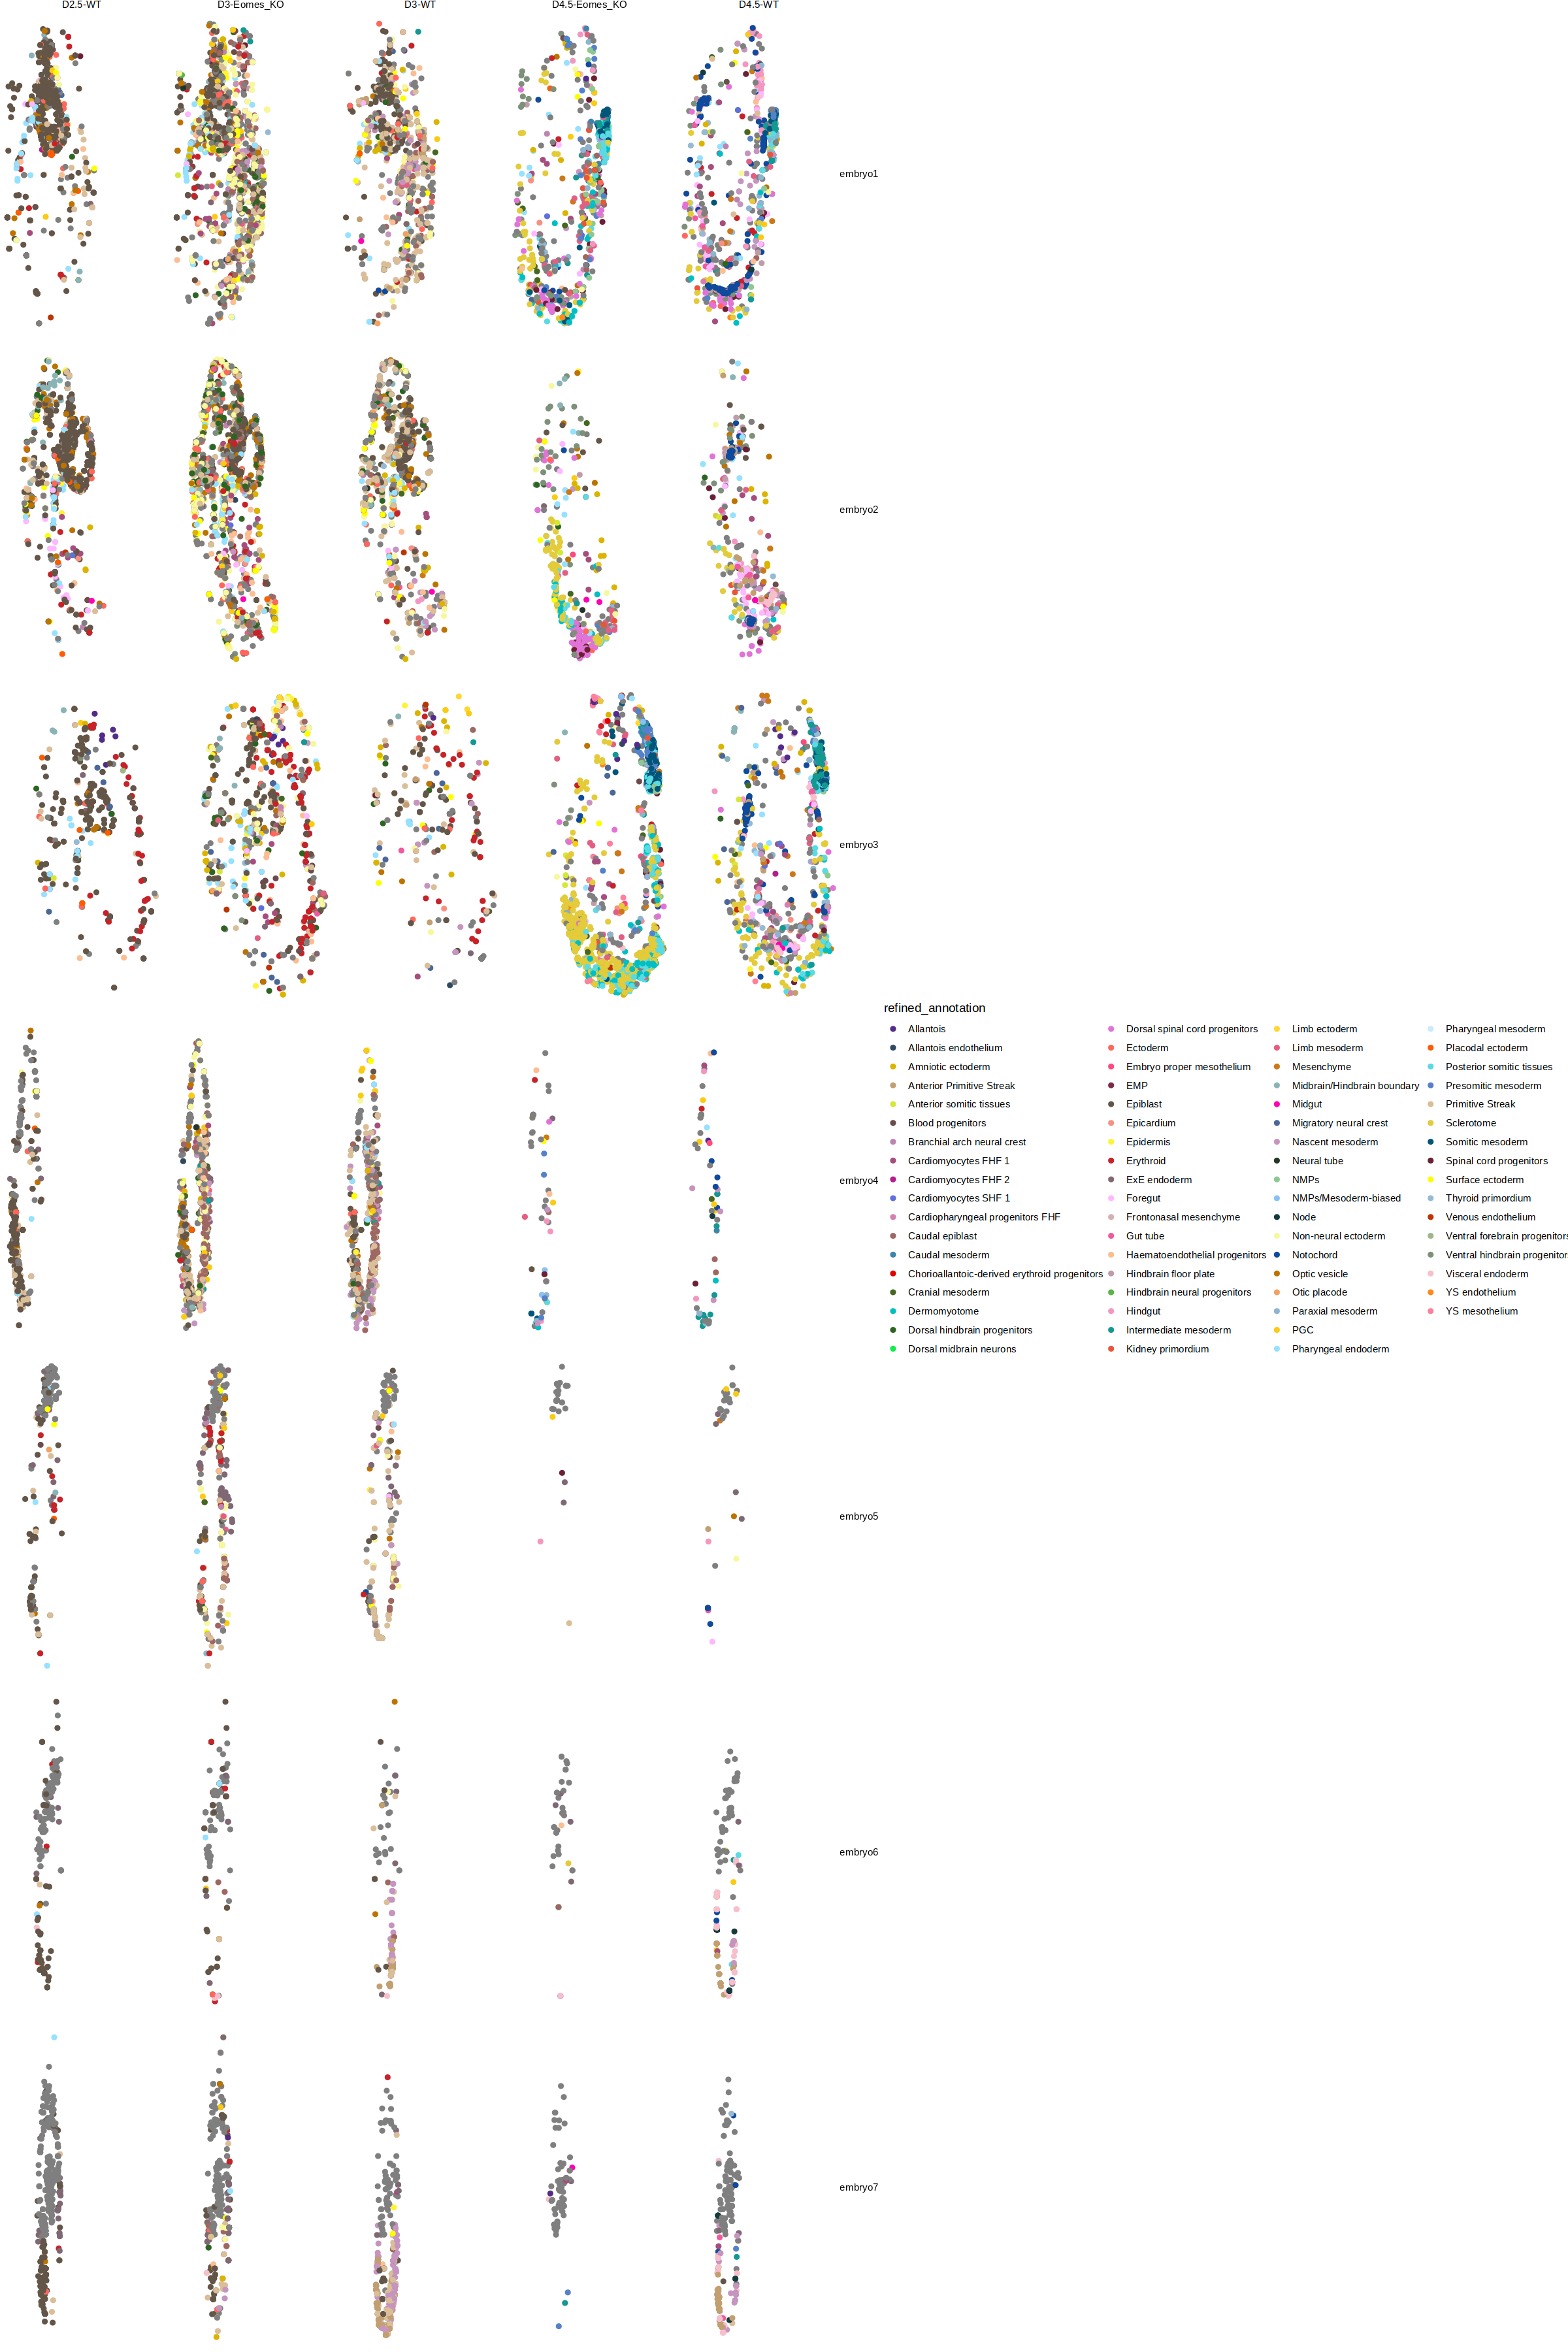

In [72]:
options(repr.plot.width = 20, repr.plot.height = 30)

ggplot(new_meta, aes(dim1, dim2, color = refined_annotation)) + 
    geom_point() + 
    scale_color_manual(values = opts$celltype_ext.colors) + 
    facet_grid(cols = vars(day_celltype), rows = vars(embryo), scales = 'free') + 
    theme_void() + 
    theme(
        legend.position = 'right'
    )


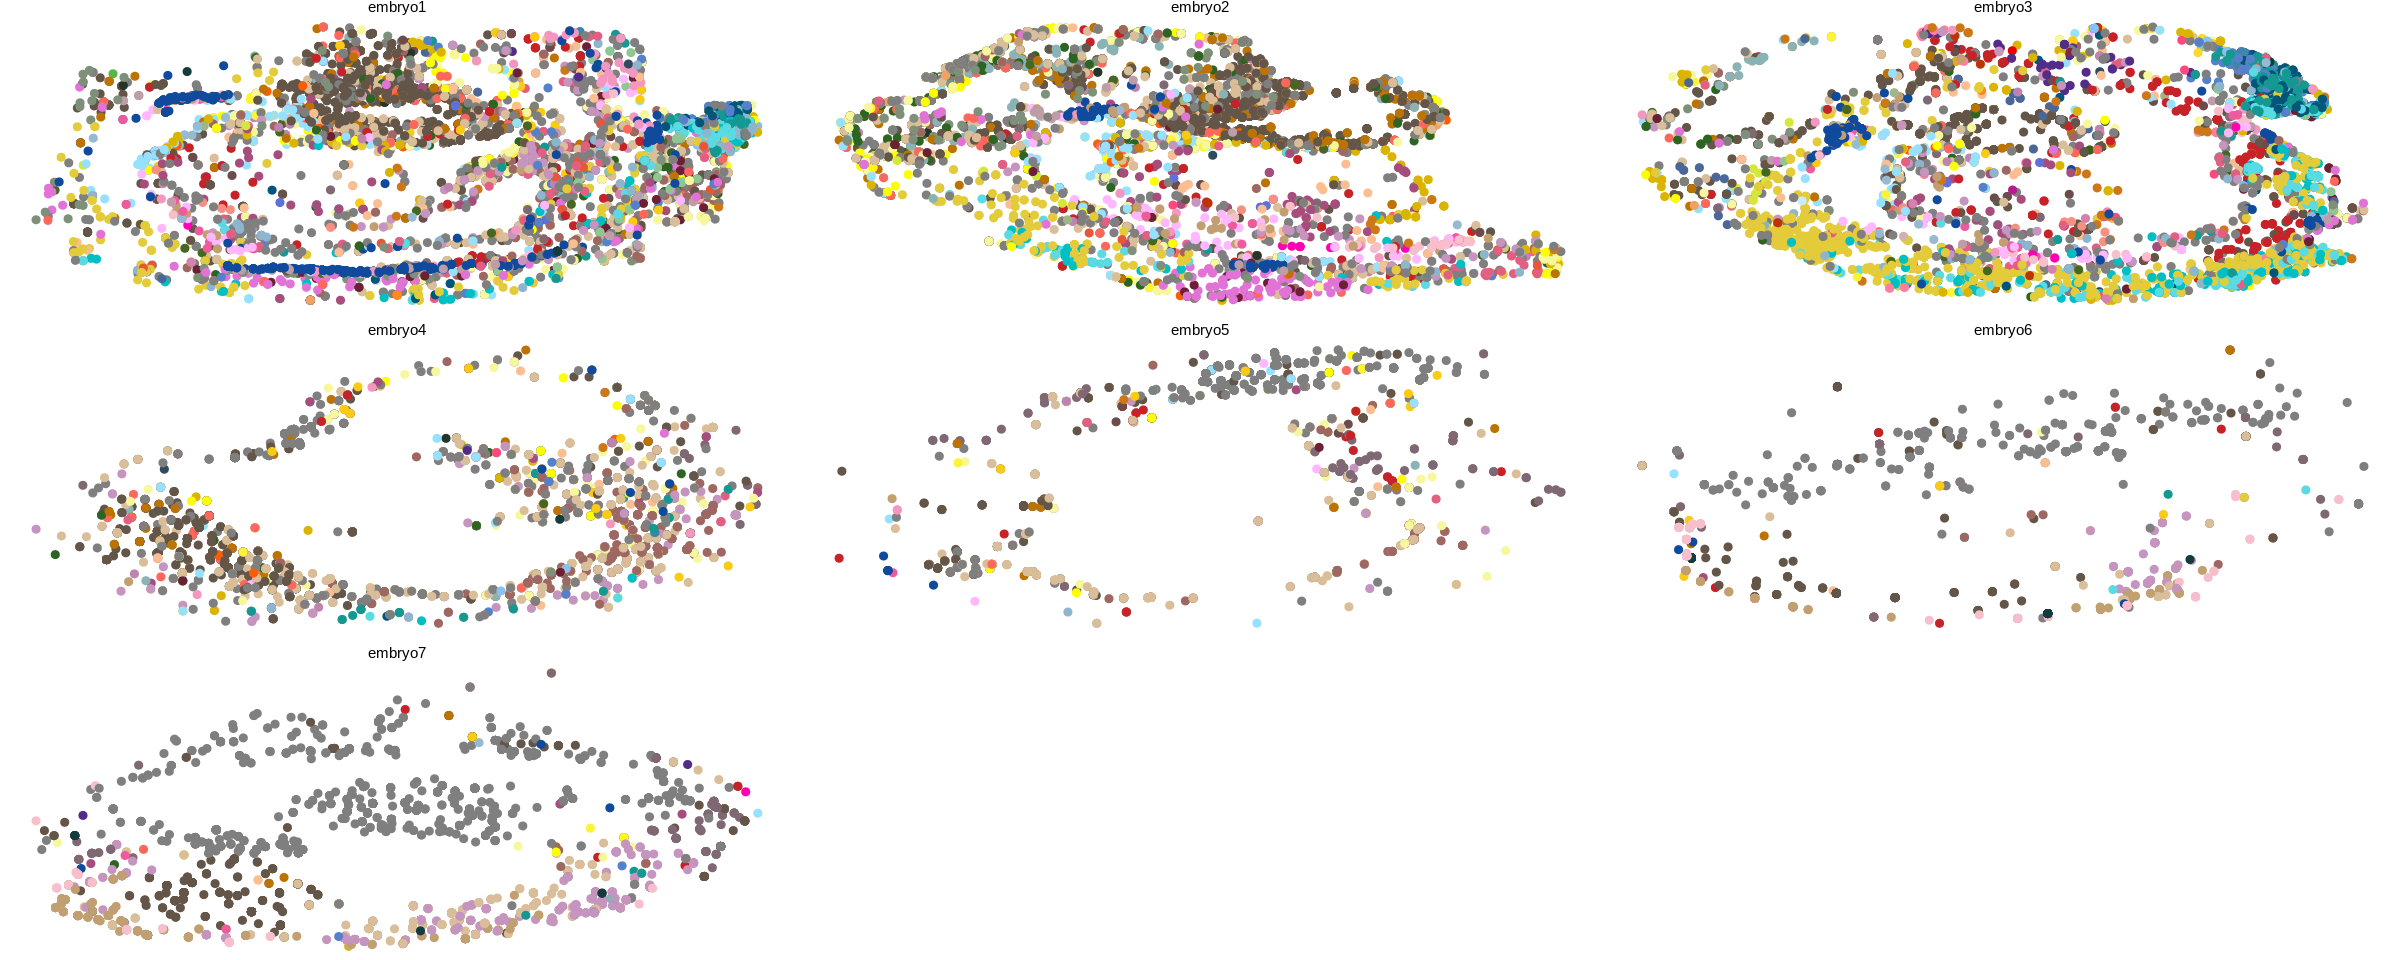

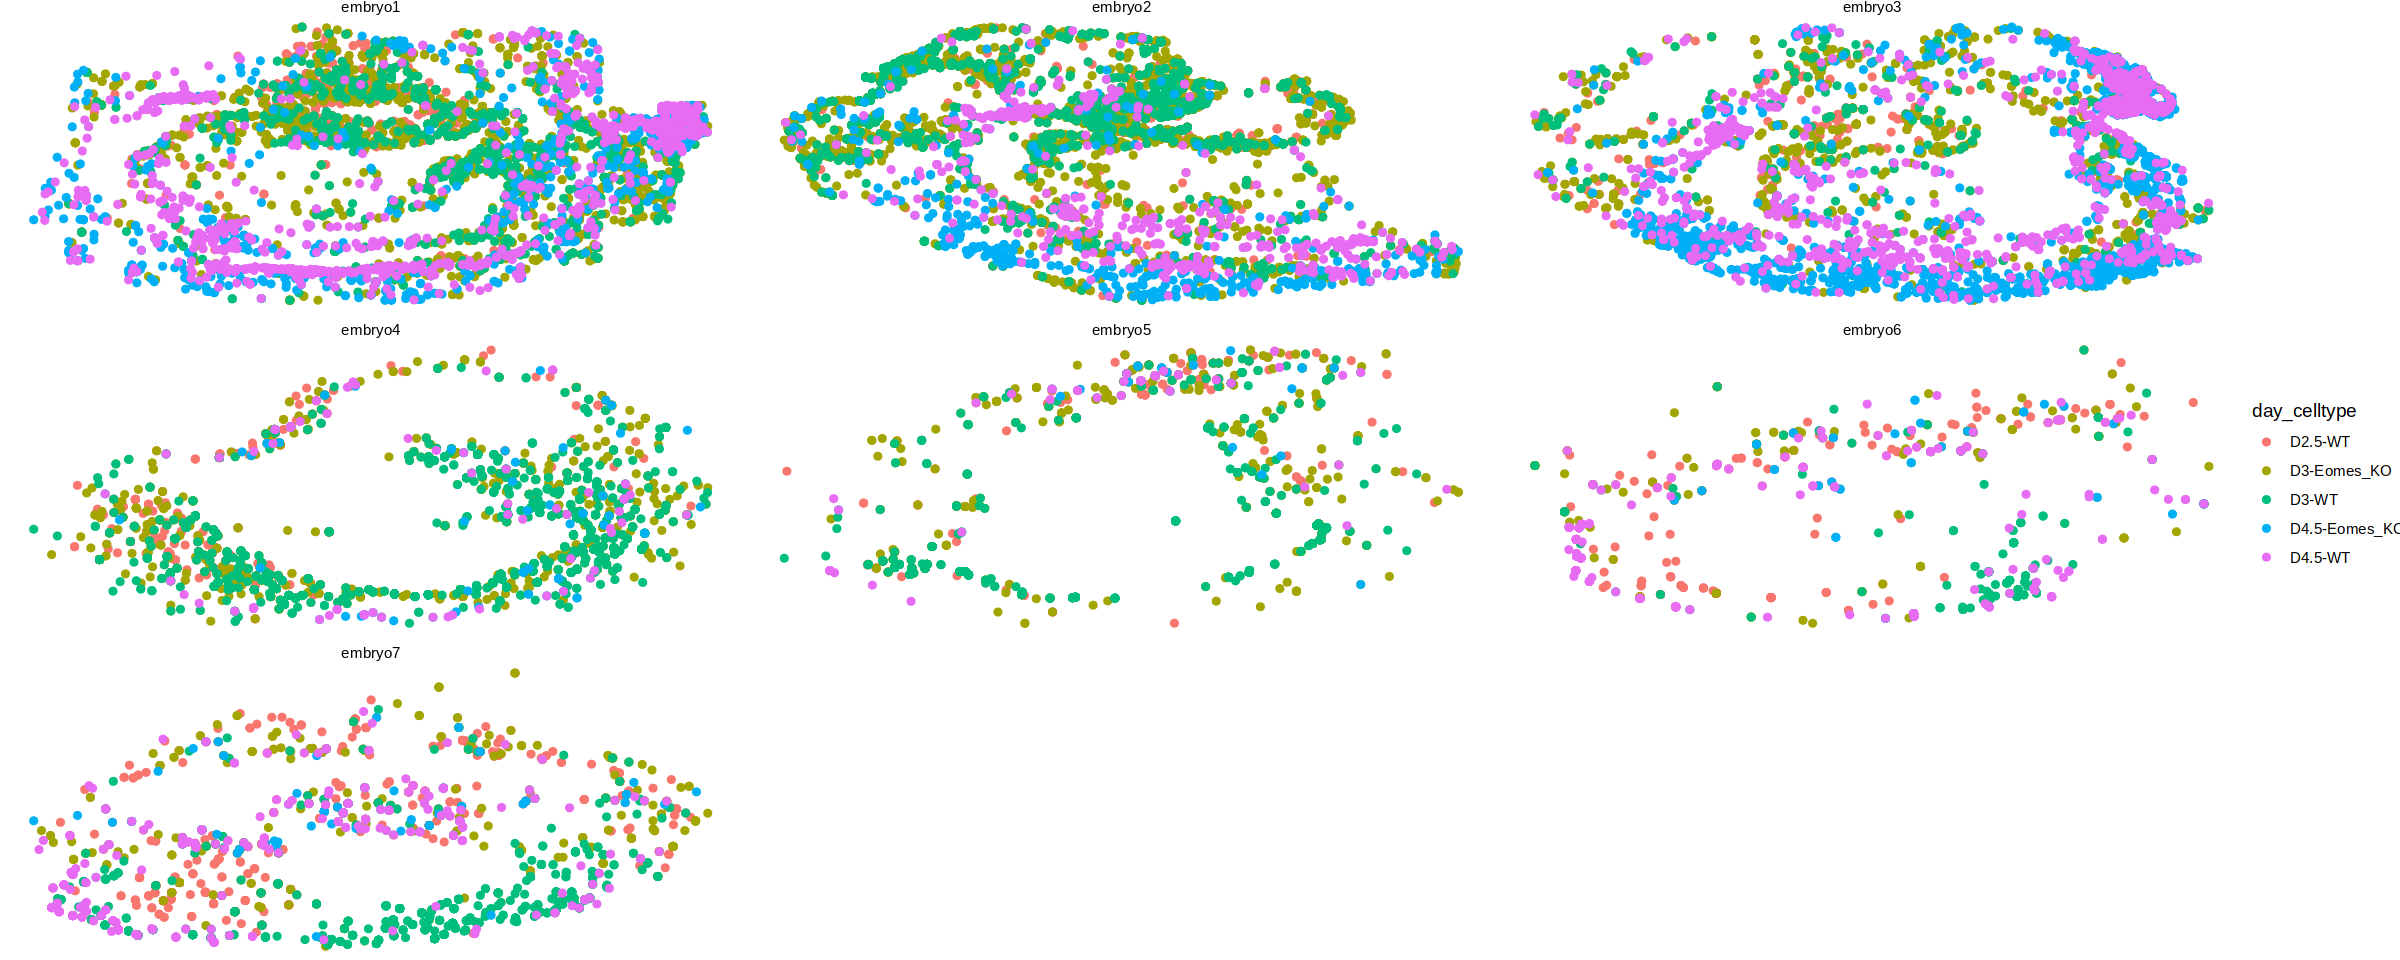

In [4]:
options(repr.plot.width = 20, repr.plot.height = 8)
ggplot(new_meta, aes(dim1, dim2, color = refined_annotation)) + 
    geom_point() + 
    scale_color_manual(values = opts$celltype_ext.colors) + 
    facet_wrap(~embryo, scales = 'free') + 
    theme_void() + 
    theme(
        legend.position = 'none'
    )

ggplot(new_meta, aes(dim1, dim2, color = day_celltype)) + 
    geom_point() + 
    facet_wrap(~embryo, scales = 'free') + 
    theme_void()

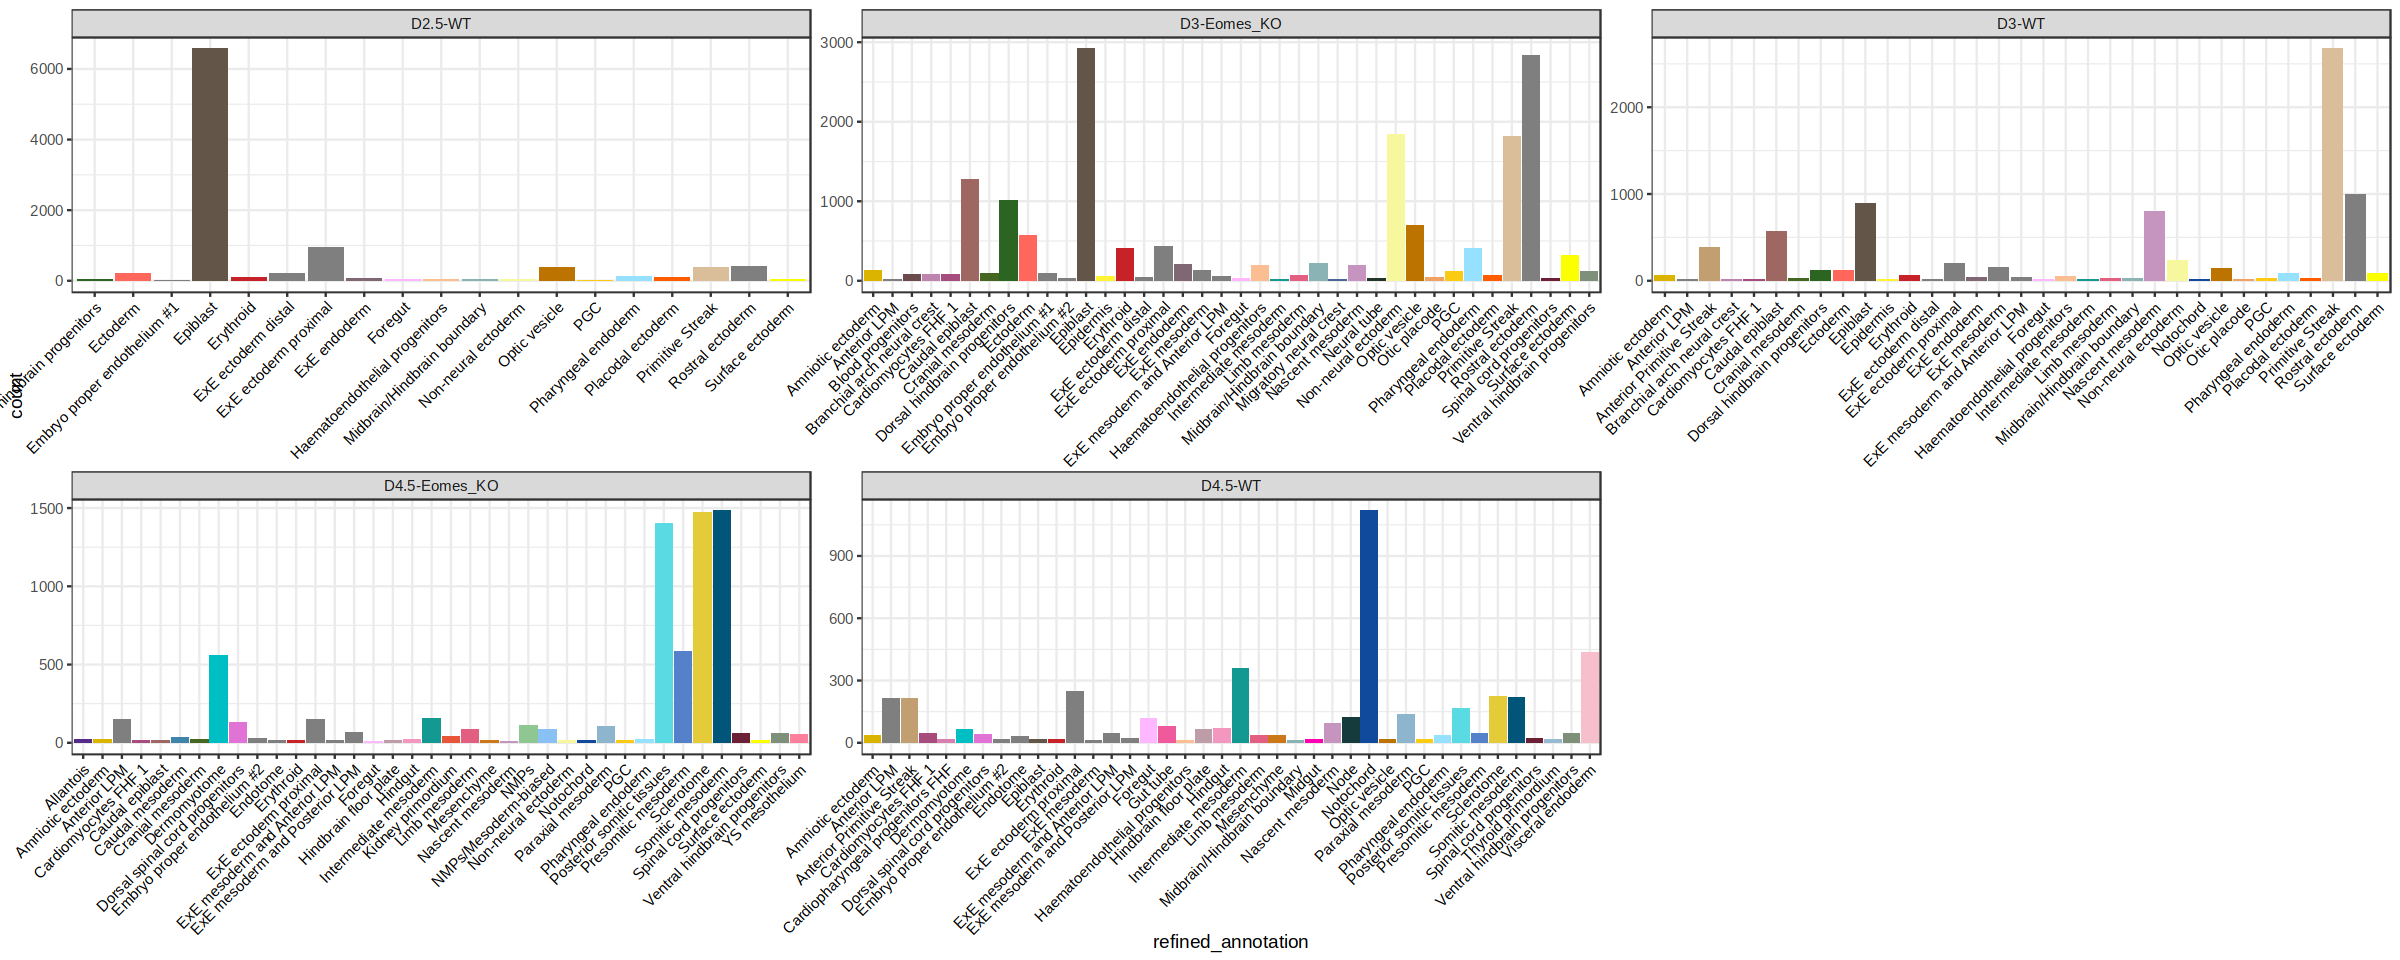

In [49]:
plot = new_meta %>% as.data.table() %>% copy() %>%
    .[, count := .N, by = .(refined_annotation,day_celltype)] %>%
    unique(by = c('refined_annotation','day_celltype')) %>%
    .[count > 10]

ggplot(plot, aes(refined_annotation, count, fill = refined_annotation)) + 
    geom_bar(stat = 'identity') + 
    facet_wrap(~day_celltype, scales = 'free') + 
    scale_fill_manual(values = opts$celltype_ext.colors) + 
    theme_bw() + 
    theme(
        legend.position = 'none',
        axis.text.x = element_text(angle = 45, hjust = 1, vjust = 1, color = 'black'),
        text = element_text(color = 'black')
    )

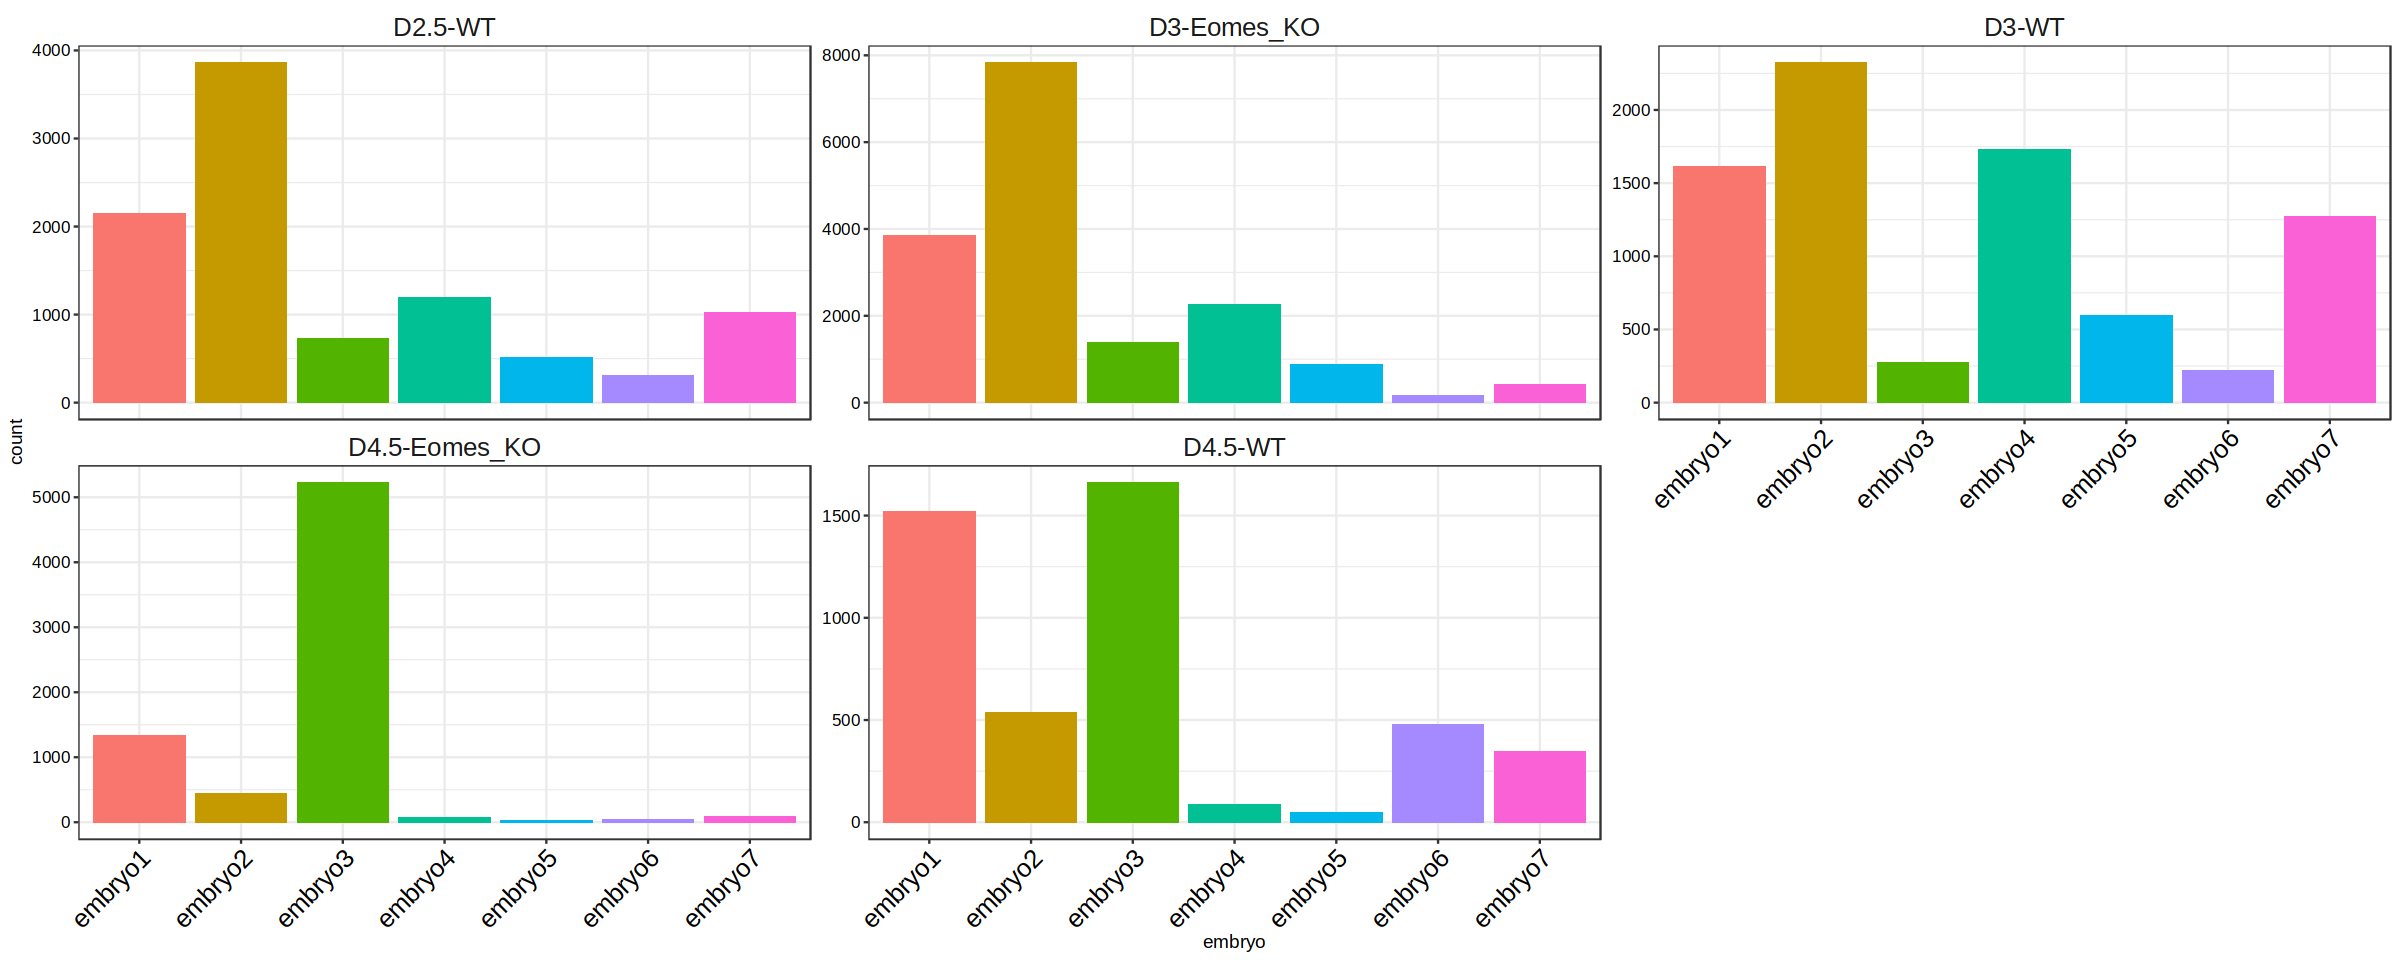

In [54]:
plot = new_meta %>% as.data.table() %>% copy() %>%
    .[, count := .N, by = .(embryo,day_celltype)] %>%
    unique(by = c('embryo','day_celltype')) 

ggplot(plot, aes(embryo, count, fill = embryo)) + 
    geom_bar(stat = 'identity') + 
    facet_wrap(~day_celltype, scales = 'free_y') + 
    theme_bw() + 
    theme(
        legend.position = 'none',
        axis.text.x = element_text(angle = 45, hjust = 1, vjust = 1, size = 15, color = 'black'),
        axis.text = element_text(color = 'black', size = 10),
        strip.text = element_text(size = 15),
        strip.background = element_blank()
    )

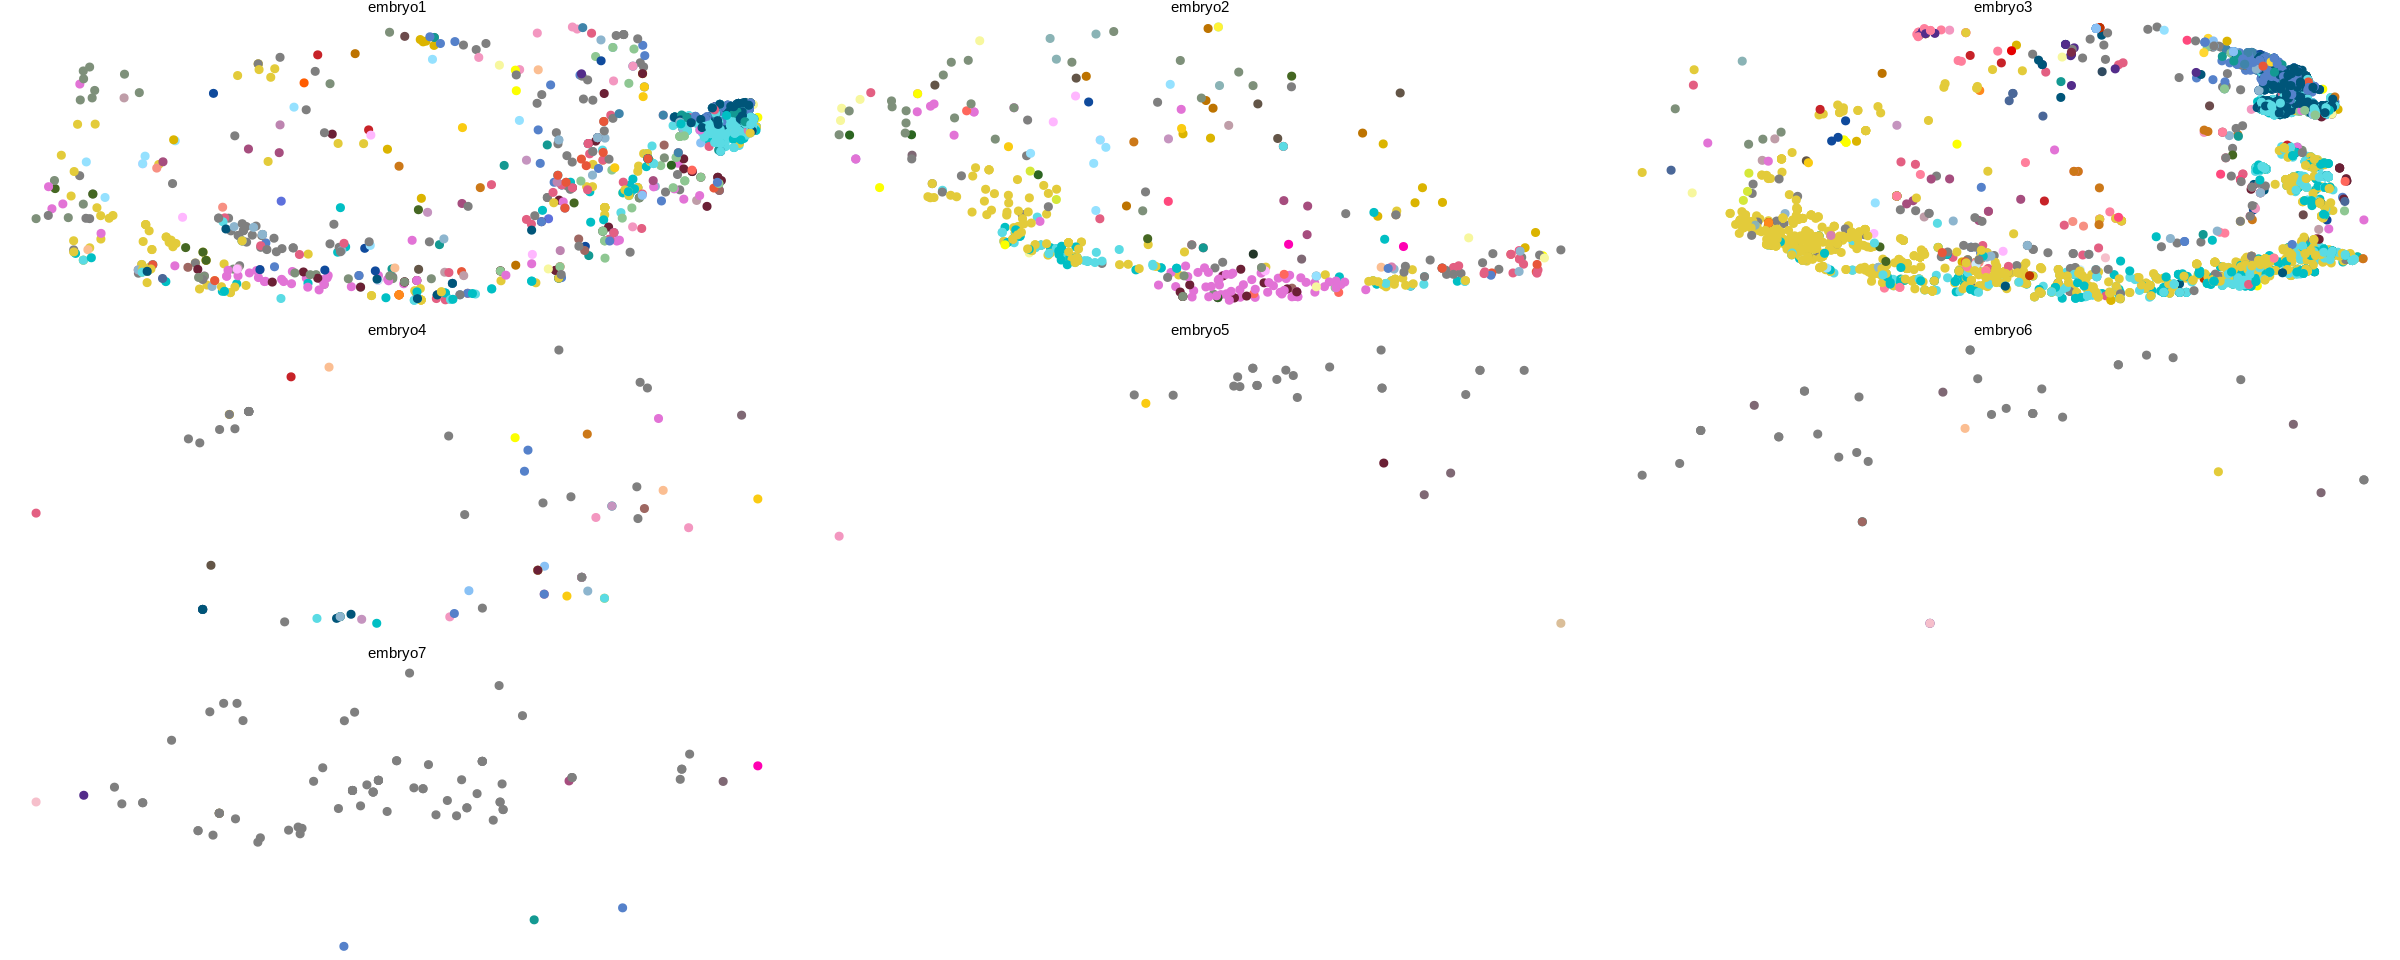

In [64]:
ggplot(as.data.table(new_meta)[day_celltype == 'D4.5-Eomes_KO'], aes(dim1, dim2, color = refined_annotation)) + 
    geom_point() + 
    scale_color_manual(values = opts$celltype_ext.colors) + 
    facet_wrap(~embryo, scales = 'free') + 
    theme_void() + 
    theme(
        legend.position = 'none'
    )

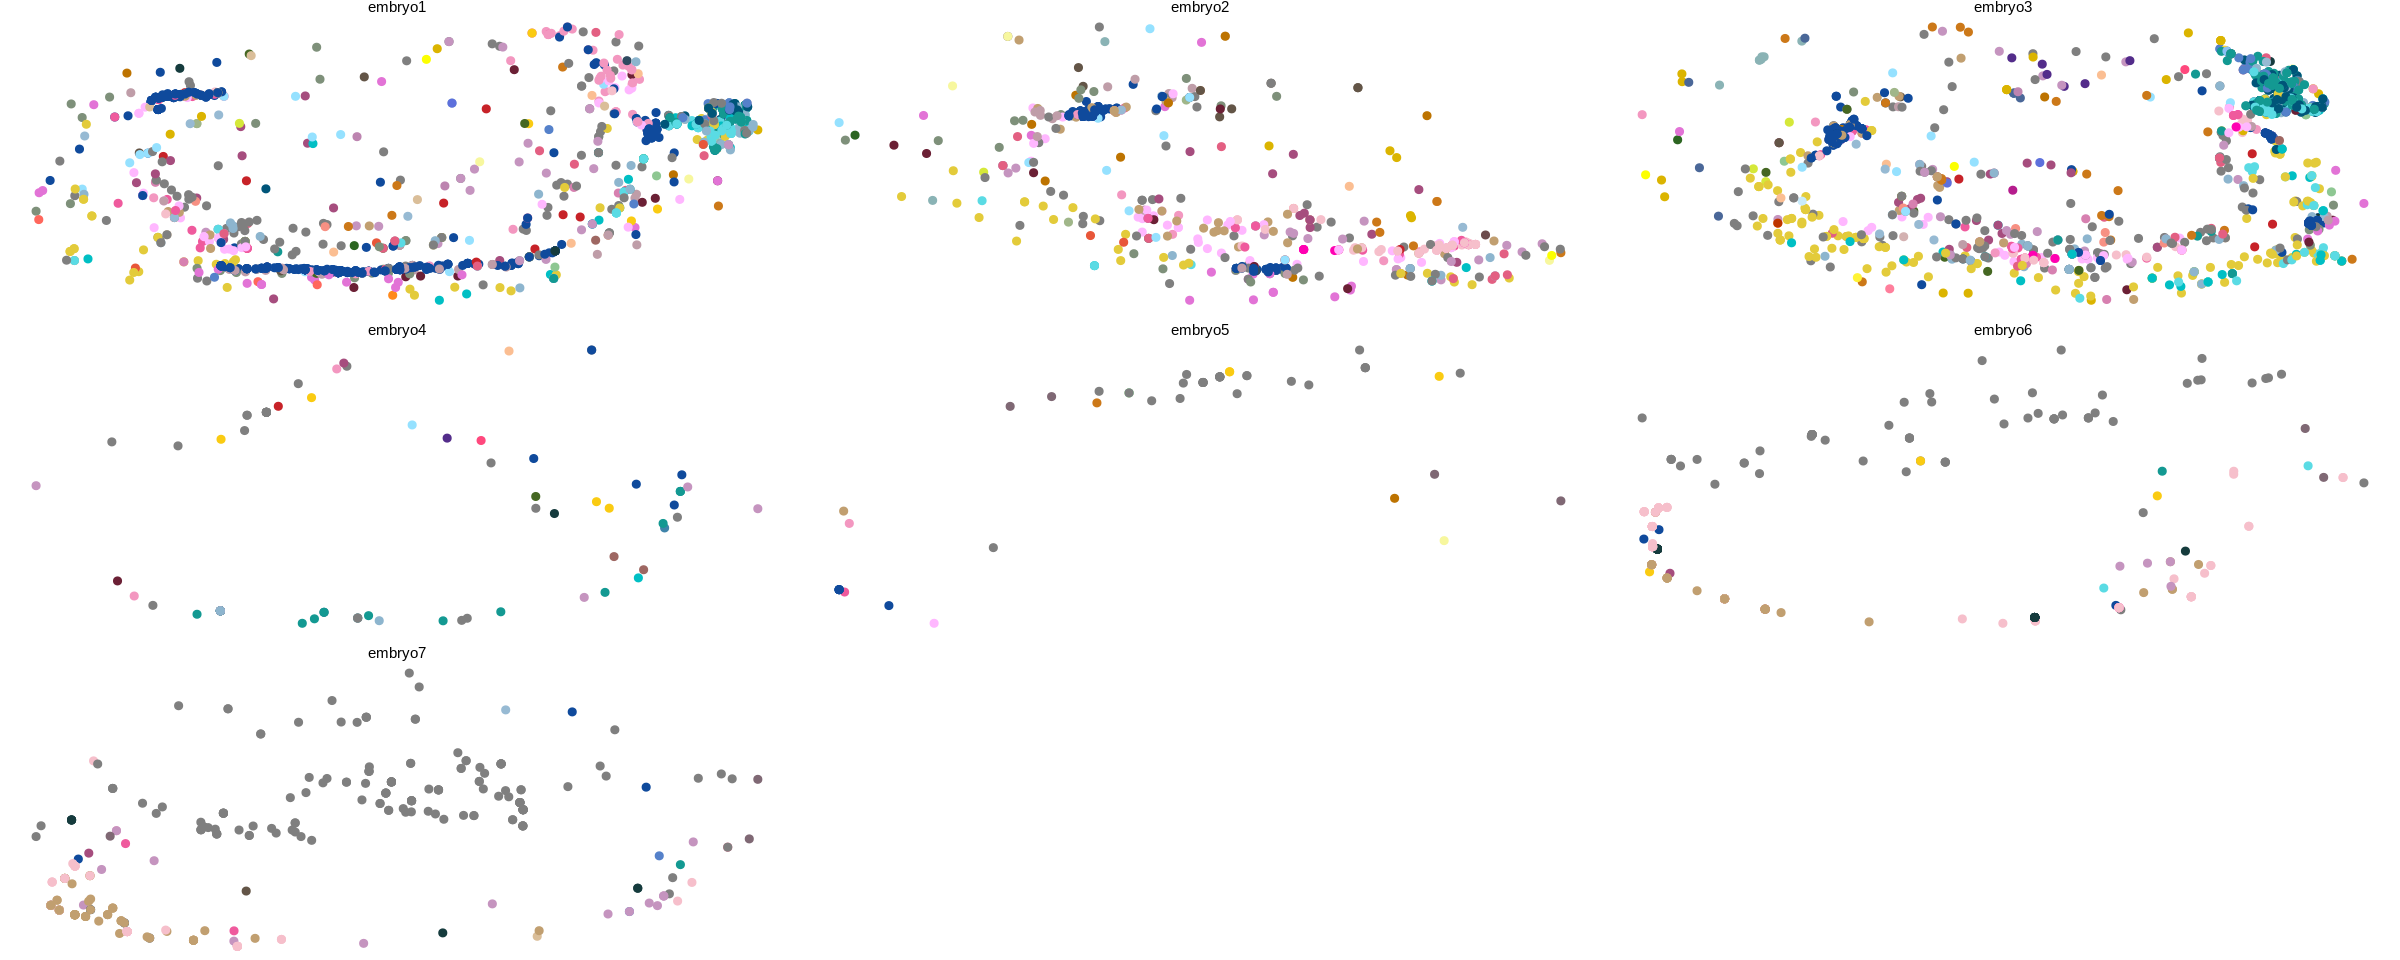

In [65]:
ggplot(as.data.table(new_meta)[day_celltype == 'D4.5-WT'], aes(dim1, dim2, color = refined_annotation)) + 
    geom_point() + 
    scale_color_manual(values = opts$celltype_ext.colors) + 
    facet_wrap(~embryo, scales = 'free') + 
    theme_void() + 
    theme(
        legend.position = 'none'
    )

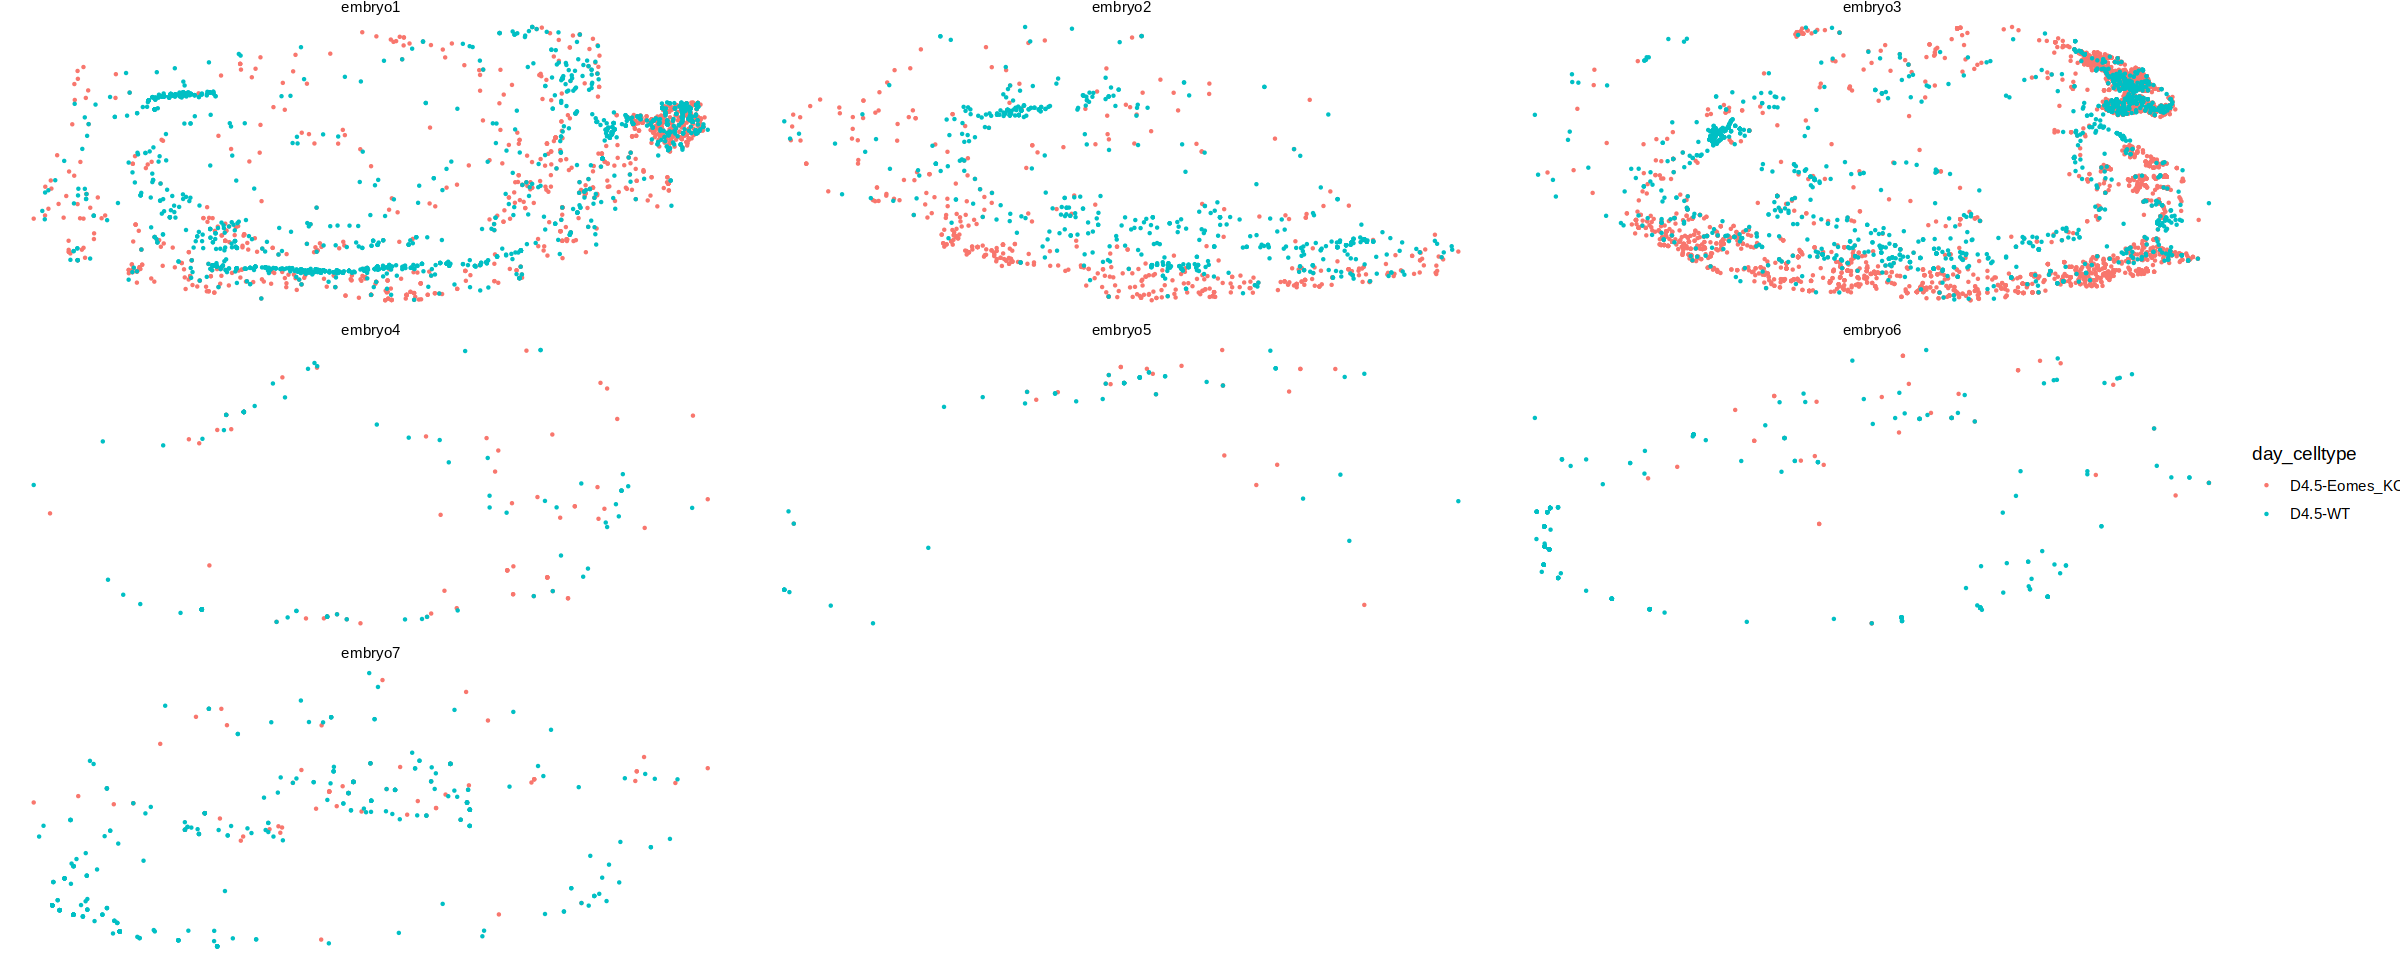

In [68]:
ggplot(as.data.table(new_meta)[day_celltype == 'D4.5-WT' | day_celltype == 'D4.5-Eomes_KO'], aes(dim1, dim2, color = day_celltype)) + 
    geom_point(size = 0.2) + 
    facet_wrap(~embryo, scales = 'free') + 
    theme_void() + 
    theme(
    )

In [10]:
opts$celltype.colors

Epiblast               Primitive_Streak 
                     "#635547"                      "#DABE99" 
               Caudal_epiblast                            PGC 
                     "#9e6762"                      "#FACB12" 
     Anterior_Primitive_Streak                      Notochord 
                     "#c19f70"                      "#0F4A9C" 
                 Def._endoderm                            Gut 
                     "#F397C0"                      "#EF5A9D" 
              Nascent_mesoderm                 Mixed_mesoderm 
                     "#C594BF"                      "#DFCDE4" 
         Intermediate_mesoderm                Caudal_Mesoderm 
                     "#139992"                      "#3F84AA" 
             Paraxial_mesoderm               Somitic_mesoderm 
                     "#8DB5CE"                      "#005579" 
           Pharyngeal_mesoderm                 Cardiomyocytes 
                     "#C9EBFB"                      "#B51D8D" 
                     Allantois                   ExE_mesoderm 
                     "#532C8A"                      "#8870ad" 
                    Mesenchyme Haematoendothelial_progenitors 
                     "#cc7818"                      "#FBBE92" 
                   Endothelium              Blood_progenitors 
                     "#ff891c"                      "#c9a997" 
           Blood_progenitors_1            Blood_progenitors_2 
                     "#f9decf"                      "#c9a997" 
                     Erythroid                     Erythroid1 
                     "#EF4E22"                      "#C72228" 
                    Erythroid2                     Erythroid3 
                     "#f79083"                      "#EF4E22" 
                           NMP                   Neurectoderm 
                     "#8EC792"                      "#65A83E" 
          Rostral_neurectoderm            Caudal_neurectoderm 
                     "#65A83E"                      "#354E23" 
                  Neural_crest   Forebrain_Midbrain_Hindbrain 
                     "#C3C388"                      "#647a4f" 
                   Spinal_cord               Surface_ectoderm 
                     "#CDE088"                      "#f7f79e" 
             Visceral_endoderm                   ExE_endoderm 
                     "#F6BFCB"                      "#7F6874" 
                  ExE_ectoderm              Parietal_endoderm 
                     "#989898"                      "#1A1A1A"

In [15]:
table(new_meta$embryo)


embryo1 embryo2 embryo3 embryo4 embryo5 embryo6 embryo7 
  10466   15007    9295    5349    2065    1223    3142 

In [5]:
new_meta

celltype,day_celltype,cell_ID,AP,DV,joint_clusters_pass_QC,refined_annotation,UMAP_1,UMAP_2,dim1,dim2,embryo,nearest_cell,nearest_cell_seqFISH,dataset
<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
Epiblast,D2.5-WT,RBG43471#AAACAGCCAACACTTG-1,82.38506,74.09753,TRUE,Epiblast,-9.723248,6.1272333,776.6756,1048.1910,embryo2,embryo2_Pos35_cell315,embryo2_Pos40_cell11,query
Epiblast,D2.5-WT,RBG43471#AAACAGCCACATACTG-1,NA,NA,TRUE,Epiblast,-8.626594,1.4200865,136.2194,261.6634,embryo4,cell_107318,embryo4_Pos0_cell917,query
Epiblast,D2.5-WT,RBG43471#AAACAGCCACGAATTT-1,86.62183,77.55485,TRUE,Epiblast,-9.015120,1.7139353,605.2061,1188.3240,embryo1,cell_2213,embryo1_Pos5_cell340,query
Rostral_neurectoderm,D2.5-WT,RBG43471#AAACAGCCAGTTAGCC-1,92.95205,74.17337,TRUE,Epiblast,-8.214499,1.0885097,823.0177,777.5239,embryo1,cell_48199,embryo1_Pos15_cell296,query
Epiblast,D2.5-WT,RBG43471#AAACATGCAAGTCGCT-1,NA,NA,TRUE,Epiblast,-7.099150,1.5104707,853.7440,991.8937,embryo2,cell_78458,embryo2_Pos40_cell168,query
Primitive_Streak,D2.5-WT,RBG43471#AAACATGCAATTGAAG-1,89.60598,88.46949,TRUE,Epiblast,-7.480490,1.8356743,681.8075,1180.6235,embryo2,cell_89574,embryo2_Pos35_cell172,query
Epiblast,D2.5-WT,RBG43471#AAACATGCACCAGCAT-1,92.77456,67.99013,TRUE,Epiblast,-7.806910,6.3471158,605.2061,1188.3240,embryo1,embryo2_Pos35_cell70,embryo1_Pos5_cell340,query
Epiblast,D2.5-WT,RBG43471#AAACATGCATCCAGGT-1,NA,NA,TRUE,ExE ectoderm proximal,-4.585347,-14.4853036,520.8093,727.5905,embryo5,cell_79446,embryo5_Pos0_cell86,query
Epiblast,D2.5-WT,RBG43471#AAACATGCATTTAAGC-1,NA,NA,TRUE,ExE ectoderm proximal,-4.235803,-14.3650825,586.1187,585.4230,embryo7,cell_14651,embryo7_Pos13_cell510,query
